# GridPulse — Energy Forecasting (Team 22)
Spain: electricity load, solar and wind generation + weather.

**Notebook map**
- **Part 1 — Preprocessing:** setup, load, weather + energy cleaning, master table, data-quality flags, split, save, feature engineering
- **Part 2 — EDA:** target distributions, targets vs weather, weather correlations
- **Part 3 — Modelling** (+ Optuna tuning, MLflow tracking, production model on validation, SHAP)
- **Part 4 — Anomaly detection** (new)
- **Part 5 — Business view** (new)
- **Part 6 — Serving bundle for the API** (new)

## What changed in this final version
The team's cells are kept; bugs are fixed **inside** those cells (each fix has a `# FIX:` comment), and the new sections are marked **(new)**.

| Area | Change |
|---|---|
| 1.2 Load | (new) Provenance check: the two CSV files must match the SHA-256 hashes the project was built on. |
| 1.3 Weather | FIX: column names are `temp_madrid`, not `tempmadrid`; the 2.3/2.4 EDA now sees all 55 weather columns (it saw 25). |
| 1.8 Missing values | FIX: targets and operator forecasts are no longer filled; other columns use past values only (`ffill`). `bfill` copied future values backwards. |
| 3.1 Setup | Horizon note corrected: the shortest lag is 48 h, so every prediction is a 48-h-ahead forecast. |
| 3.3 Training | FIX: a fresh model set per signal (the old loop refitted one object, so all models ended up as the wind fit); duplicate training/validation cells removed. |
| 3.4b | (new) Optuna tuning of LightGBM on time-ordered folds inside train (validation stays clean). |
| 3.6 | (new) Production model per signal chosen on **validation** (the old text chose `hist_gb` from test results). |
| 3.7 | (new) MLflow: every model, the tuning studies and the production models (Model Registry). |
| 3.8 | (new) SHAP explanations: global (beeswarm) and local (waterfall) per signal. |
| Part 4 | (new) Anomaly detection: trust rules + nowcast band + forecast band, calibrated on validation, evidence for 2018 alerts, injected-fault evaluation. |
| Part 5 | (new) Business view: cost of forecast errors, alert workload, recommendations. |
| Part 6 | (new) Export of the serving bundle (`OUT/artifacts/`) used by the FastAPI service and the Streamlit app. |

# Part 1 — Preprocessing

## 1.1 Setup

In [1]:
import json, hashlib
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Config
All thresholds, target names, ranges and split dates live here. Change them here only.

In [2]:
import os
OUT = Path(os.environ.get("GRIDPULSE_OUT", "/content/gridpulse_outputs"))   # FIX: overridable outside Colab
OUT.mkdir(parents=True, exist_ok=True)

CFG = {
    "targets":    {"load": "total load actual", "solar": "generation solar", "wind": "generation wind onshore"},
    "benchmarks": {"load": "total load forecast", "solar": "forecast solar day ahead", "wind": "forecast wind onshore day ahead"},
    "ranges_mw": {"load": (10_000, 50_000), "solar": (0, 15_000), "wind": (0, 25_000)},
    "flatline_hours": {"load": 6, "solar": 4, "wind": 8},
    "solar_night_elevation_deg": -6, "solar_night_max_mw": 2500,
    "solar_flatline_min_elevation_deg": 5, "solar_midday_elevation_deg": 25,
    "site": {"lat": 40.0, "lon": -3.7},
    "load_deviation_pct": 0.25,
    "weather_ranges": {
        "temp": (-40, 55), "temp_min": (-40, 55), "temp_max": (-40, 55),
        "pressure": (900, 1100), "humidity": (0, 100), "wind_speed": (0, 60), "wind_deg": (0, 360),
        "rain_1h": (0, 200), "rain_3h": (0, 300), "snow_3h": (0, 300), "clouds_all": (0, 100),
    },
    "weather_interp_limit_hours": 3,
    "empty_col_share": 0.999,
    "splits": {
        "train":      ("2015-01-01 00:00", "2017-01-01 00:00"),
        "validation": ("2017-01-03 00:00", "2018-01-01 00:00"),
        "test":       ("2018-01-03 00:00", "2019-01-01 00:00"),
    },
    "gap_hours": 48,
    "origin_hour_utc": 9,
}

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

## 1.2 Load raw data

In [3]:
path = kagglehub.dataset_download("nicholasjhana/energy-consumption-generation-prices-and-weather")

data_path = Path(path)

weather_path = next(data_path.rglob("weather_features.csv"))
energy_path = next(data_path.rglob("energy_dataset.csv"))

weather_raw = pd.read_csv(weather_path)
energy_raw = pd.read_csv(energy_path)
print("Weather:", weather_raw.shape, "| Energy:", energy_raw.shape)

Weather: (178396, 17) | Energy: (35064, 29)


In [4]:
# (new) Provenance: the exact files this project was built on. Any other version stops the notebook.
EXPECTED_SHA256 = {
    "energy_dataset.csv": "14cd13e020d87af0ab49db8e0f1e4d308320ec5b8d2dec23bab4d27c75c7733a",
    "weather_features.csv": "3566c3c21179d4fc6691eec6d37a6cfe8fe6a4d9e097f95e4fda4a29dc683b18",
}
provenance = {
    "dataset": "Hourly energy demand, generation and weather - Spain 2015-2018",
    "source": "https://www.kaggle.com/datasets/nicholasjhana/energy-consumption-generation-prices-and-weather",
    "license": "CC0: Public Domain",
    "original_sources": {"energy": "ENTSO-E transparency platform", "prices": "Red Electrica de Espana", "weather": "OpenWeather (5 cities)"},
    "files": {p.name: {"bytes": p.stat().st_size, "sha256": sha256_file(p)} for p in (energy_path, weather_path)},
}
for name, expected in EXPECTED_SHA256.items():
    assert provenance["files"][name]["sha256"] == expected, f"{name} is not the version this project was built on"
DATASET_VERSION = "ds-" + hashlib.sha256("".join(EXPECTED_SHA256.values()).encode()).hexdigest()[:12]
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2))
print("Raw files match the expected hashes. Dataset version:", DATASET_VERSION)

Raw files match the expected hashes. Dataset version: ds-72cce1c231a6


## 1.3 Weather cleaning
Timestamps to UTC, city names normalised, Kelvin to Celsius, out-of-range values set to NaN,
then one row per hour with a column per (variable, city).

In [5]:
w = weather_raw.copy()
w["time_utc"] = pd.to_datetime(w["dt_iso"], utc=True)
w["city"] = w["city_name"].astype(str).str.strip().str.lower().str.replace(r"\s+", "_", regex=True)

assert w["temp"].median() > 200, "temperature does not look like Kelvin"
for c in ["temp", "temp_min", "temp_max"]:
    w[c] = w[c] - 273.15

for c, (lo, hi) in CFG["weather_ranges"].items():
    bad = (w[c] < lo) | (w[c] > hi)
    print(f"{c}: {int(bad.sum())} out of range")
    w.loc[bad, c] = np.nan

cols = list(CFG["weather_ranges"])
wide = w.groupby(["time_utc", "city"])[cols].median().unstack("city")
wide.columns = [f"{v}_{c}" for v, c in wide.columns]   # FIX: was f"{v}{c}" -> "tempmadrid"; EDA filters need "temp_madrid"
print("weather wide:", wide.shape)

temp: 0 out of range
temp_min: 0 out of range
temp_max: 0 out of range
pressure: 48 out of range
humidity: 0 out of range
wind_speed: 2 out of range
wind_deg: 0 out of range
rain_1h: 0 out of range
rain_3h: 0 out of range
snow_3h: 0 out of range
clouds_all: 0 out of range
weather wide: (35064, 55)


## 1.4 Energy cleaning + master table
Build a clean table with one row per hour (`master`), keep the targets untouched, and join the weather.

In [6]:
e = energy_raw.copy()
e["time_utc"] = pd.to_datetime(e["time"], utc=True)
e = e.drop_duplicates("time_utc").drop(columns="time").set_index("time_utc").sort_index()

grid = pd.date_range(e.index.min(), e.index.max(), freq="h", tz="UTC", name="time_utc")
e = e.reindex(grid)

keep = set(CFG["targets"].values()) | set(CFG["benchmarks"].values())
empty_share = (e.isna() | (e == 0)).mean()
e = e.drop(columns=[c for c in e.columns if c not in keep and empty_share[c] >= CFG["empty_col_share"]])

wide = wide.reindex(grid)
before = wide.isna()
wide = wide.interpolate(method="time", limit=CFG["weather_interp_limit_hours"], limit_area="inside")
n_weather_imputed = (before & wide.notna()).sum(axis=1).rename("n_weather_imputed")

master = e.join(wide).join(n_weather_imputed)
gen = [c for c in master.columns if c.startswith("generation ")]
master["missing_generation_count"] = master[gen].isna().sum(axis=1)
master["generation_features_complete"] = (master["missing_generation_count"] == 0)

print("master:", master.shape)
assert master.index.is_unique

master: (35064, 78)


## 1.5 Data-quality flags (trust layer)
This section evaluates the quality and reliability of energy target data

by identifying missing values, out-of-range readings, prolonged constant

values, and potential anomalies specific to solar generation and electricity load.

It calculates solar elevation using the site's geographic coordinates to

support solar-specific quality checks, such as detecting unexpected nighttime

generation and zero output during periods of high solar elevation.

Each target is assigned a data quality status (valid, data_error, or

suspected_anomaly), along with the corresponding reason labels.

Separate usability flags indicate whether target values are available
and free from the defined data error conditions.

The section also assesses generation feature completeness and summarizes

the detected quality statuses and reasons for each target.

Finally, it exports the quality summary and the configuration rules to JSON

files to support traceability, review, and reproducibility.

In [7]:
def solar_elevation_deg(index, lat, lon):
    t = index + pd.Timedelta(minutes=30)
    doy = np.asarray(t.dayofyear, dtype=float)
    hour = np.asarray(t.hour, dtype=float) + np.asarray(t.minute, dtype=float) / 60


    g = 2 * np.pi / 365 * (doy - 1 + (hour - 12) / 24)
    eqtime = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    ha = np.deg2rad((hour * 60 + eqtime + 4 * lon) / 4 - 180)
    la = np.deg2rad(lat)
    cos_zenith = np.sin(la) * np.sin(decl) + np.cos(la) * np.cos(decl) * np.cos(ha)
    return pd.Series(90 - np.degrees(np.arccos(np.clip(cos_zenith, -1, 1))), index=index)

def flatline(s, n):
    group = (s != s.shift()).cumsum()
    return (s.groupby(group).transform("size") >= n) & s.notna()

def reasons(rules):
    df = pd.DataFrame(rules, index=master.index).fillna(False).astype(bool)
    text = df.apply(lambda row: ";".join(df.columns[row.to_numpy()]), axis=1)
    return text, df.any(axis=1)

elev = solar_elevation_deg(master.index, CFG["site"]["lat"], CFG["site"]["lon"])
master["sun_elevation_deg"] = elev.round(2)

for sig, col in CFG["targets"].items():
    s = master[col]
    lo, hi = CFG["ranges_mw"][sig]
    flat_scope = (elev > CFG["solar_flatline_min_elevation_deg"]) if sig == "solar" else pd.Series(True, index=master.index)
    errors = {
        "missing_value": s.isna(),
        "out_of_range": (s < lo) | (s > hi),
        "flatline": flatline(s, CFG["flatline_hours"][sig]) & (s != 0) & flat_scope,
    }
    suspects = {}
    if sig == "solar":
        errors["night_output"] = (elev < CFG["solar_night_elevation_deg"]) & (s > CFG["solar_night_max_mw"])
        suspects["midday_zero"] = (elev > CFG["solar_midday_elevation_deg"]) & (s == 0)
    if sig == "load":
        ref = pd.concat([s.shift(168 * k) for k in (1, 2, 3, 4)], axis=1).median(axis=1)
        suspects["far_from_same_hour_last_4_weeks"] = ((s - ref).abs() / ref) > CFG["load_deviation_pct"]

    err_text, err_any = reasons(errors)
    sus_text, sus_any = reasons(suspects) if suspects else (pd.Series("", index=master.index), pd.Series(False, index=master.index))
    master[f"dq_{sig}"] = np.where(err_any, "data_error", np.where(sus_any, "suspected_anomaly", "valid"))
    master[f"dq_reason_{sig}"] = np.where(err_any, err_text, sus_text)
    master[f"usable_{sig}"] = s.notna() & ~err_any

master["feature_quality_status"] = np.where(master["generation_features_complete"], "complete", "feature_missing")

summary = {}
for sig in CFG["targets"]:
    reason_counts = master[f"dq_reason_{sig}"].str.split(";").explode()
    summary[sig] = {
        "flags": master[f"dq_{sig}"].value_counts().to_dict(),
        "reasons": reason_counts[reason_counts != ""].value_counts().to_dict(),
    }
(OUT / "trust_layer_summary.json").write_text(json.dumps(summary, indent=2, default=int))
(OUT / "trust_layer_rules.json").write_text(json.dumps({k: v for k, v in CFG.items() if k != "splits"}, indent=2, default=str))
print(json.dumps(summary, indent=2, default=int))

{
  "load": {
    "flags": {
      "valid": 33699,
      "suspected_anomaly": 1329,
      "data_error": 36
    },
    "reasons": {
      "far_from_same_hour_last_4_weeks": 1329,
      "missing_value": 36
    }
  },
  "solar": {
    "flags": {
      "valid": 34970,
      "data_error": 93,
      "suspected_anomaly": 1
    },
    "reasons": {
      "night_output": 62,
      "missing_value": 18,
      "flatline": 13,
      "midday_zero": 1
    }
  },
  "wind": {
    "flags": {
      "valid": 35046,
      "data_error": 18
    },
    "reasons": {
      "missing_value": 18
    }
  }
}


## 1.6 Train / validation / test split
Time-based split with a 48 h gap between sets.

In [8]:
gap = pd.Timedelta(hours=CFG["gap_hours"])
bounds = {k: (pd.Timestamp(a, tz="UTC"), pd.Timestamp(b, tz="UTC")) for k, (a, b) in CFG["splits"].items()}

master["split"] = "outside_or_gap"
for name, (a, b) in bounds.items():
    master.loc[(master.index >= a) & (master.index < b), "split"] = name

names = list(bounds)
for first, second in zip(names[:-1], names[1:]):
    assert bounds[second][0] - bounds[first][1] == gap, f"gap between {first} and {second} is not 48 h"

ta, tb = bounds["test"]
origins = master.index[(master.index >= ta) & (master.index <= tb - gap) & (master.index.hour == CFG["origin_hour_utc"])]
print(master["split"].value_counts())
print("test origins:", len(origins))

split
train             17544
validation         8712
test               8711
outside_or_gap       97
Name: count, dtype: int64
test origins: 361


## 1.8 Feature engineering

### Time features

In [9]:
master["hour"] = master.index.hour
master["day_of_week"] = master.index.dayofweek
master["month"] = master.index.month
master["is_weekend"] = (master["day_of_week"] >= 5).astype(int)

# Cyclical encoding
master["hour_sin"] = np.sin(2 * np.pi * master["hour"] / 24)
master["hour_cos"] = np.cos(2 * np.pi * master["hour"] / 24)
master["month_sin"] = np.sin(2 * np.pi * (master["month"] - 1) / 12)
master["month_cos"] = np.cos(2 * np.pi * (master["month"] - 1) / 12)

# Raw hour / month are replaced by their sin/cos versions
master.drop(columns=["hour", "month"], errors="ignore", inplace=True)

master[["day_of_week", "is_weekend", "hour_sin", "hour_cos", "month_sin", "month_cos"]].head()

,day_of_week,is_weekend,hour_sin,hour_cos,month_sin,month_cos
time_utc,,,,,,
2014-12-31 23:00:00+00:00,2,0,-0.258819,0.965926,-0.5,0.866025
2015-01-01 00:00:00+00:00,3,0,0.000000,1.000000,0.0,1.000000
2015-01-01 01:00:00+00:00,3,0,0.258819,0.965926,0.0,1.000000
2015-01-01 02:00:00+00:00,3,0,0.500000,0.866025,0.0,1.000000
2015-01-01 03:00:00+00:00,3,0,0.707107,0.707107,0.0,1.000000


### Lag features

In [10]:
targets = ["total load actual","generation solar","generation wind onshore"]

lags = [1, 24, 48, 72, 168, 336]

for target in targets:
    for lag in lags:
        master[f"{target}_lag_{lag}h"] = master[target].shift(lag)

### Missing values

In [11]:
master.isnull().sum()

generation biomass                       19
generation fossil brown coal/lignite     18
generation fossil gas                    18
generation fossil hard coal              18
generation fossil oil                    19
                                       ... 
generation wind onshore_lag_24h          42
generation wind onshore_lag_48h          66
generation wind onshore_lag_72h          90
generation wind onshore_lag_168h        186
generation wind onshore_lag_336h        354
Length: 114, dtype: int64

> **Fixed:** targets and operator forecasts are no longer filled (their gaps are data errors the trust layer must see), and the other columns are filled with **past** values only (`ffill`). The old `bfill` copied future values backwards.

In [12]:
# Fill missing values in original numeric columns
numeric_columns = master.select_dtypes(include="number").columns

# FIX: targets/benchmarks untouched; past values only (bfill pulled future values backwards)
untouched = list(CFG["targets"].values()) + list(CFG["benchmarks"].values())
fill_columns = [c for c in numeric_columns if c not in untouched]
master[fill_columns] = master[fill_columns].ffill()

# Remove rows where lag features are still missing
lag_columns = [col for col in master.columns if "_lag_" in col]

master = master.dropna(subset=lag_columns).copy()

print("Remaining missing values outside targets/benchmarks:", int(master.drop(columns=untouched).isnull().sum().sum()))
print("Missing target/benchmark hours (kept, flagged by the trust layer):", master[untouched].isna().sum().to_dict())

Remaining missing values outside targets/benchmarks: 0
Missing target/benchmark hours (kept, flagged by the trust layer): {'total load actual': 30, 'generation solar': 11, 'generation wind onshore': 11, 'total load forecast': 0, 'forecast solar day ahead': 0, 'forecast wind onshore day ahead': 0}


### Encoding

In [13]:
# Encoding Categorical Features

categorical_columns = master.select_dtypes(include=["object", "category"]).columns.tolist()

print("Categorical Columns:", categorical_columns)

master = pd.get_dummies(master,columns=categorical_columns,dtype=int)

print("Shape After Encoding:", master.shape)

print("Remaining Categorical Columns:",
      master.select_dtypes(include=["object", "category"]).columns.tolist())

Categorical Columns: ['dq_load', 'dq_reason_load', 'dq_solar', 'dq_reason_solar', 'dq_wind', 'dq_reason_wind', 'feature_quality_status', 'split']


Shape After Encoding: (34728, 130)
Remaining Categorical Columns: []


/tmp/ipykernel_2284/1077453107.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = master.select_dtypes(include=["object", "category"]).columns.tolist()


# Part 2 — EDA

## 2.1 Dataset overview

In [14]:
print("Rows:", master.shape[0])
print("Columns:", master.shape[1])

Rows: 34728
Columns: 130


In [15]:
master.head()

,generation biomass,generation fossil brown coal/lignite,generation fossil gas,generation fossil hard coal,generation fossil oil,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation nuclear,generation other,...,dq_wind_data_error,dq_wind_valid,dq_reason_wind_,dq_reason_wind_missing_value,feature_quality_status_complete,feature_quality_status_feature_missing,split_outside_or_gap,split_test,split_train,split_validation
time_utc,,,,,,,,,,,,,,,,,,,,,
2015-01-14 23:00:00+00:00,499.0,792.0,3825.0,6296.0,286.0,878.0,924.0,972.0,7105.0,80.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 00:00:00+00:00,494.0,730.0,3485.0,5599.0,276.0,2130.0,795.0,993.0,7103.0,80.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 01:00:00+00:00,464.0,553.0,3466.0,4801.0,293.0,2655.0,798.0,694.0,7103.0,79.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 02:00:00+00:00,464.0,573.0,3536.0,4487.0,296.0,3060.0,821.0,604.0,7103.0,80.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 03:00:00+00:00,463.0,567.0,3469.0,4427.0,294.0,3124.0,824.0,555.0,7104.0,80.0,...,0,1,1,0,1,0,0,0,1,0


In [16]:
master.dtypes

generation biomass                        float64
generation fossil brown coal/lignite      float64
generation fossil gas                     float64
generation fossil hard coal               float64
generation fossil oil                     float64
                                           ...   
feature_quality_status_feature_missing      int64
split_outside_or_gap                        int64
split_test                                  int64
split_train                                 int64
split_validation                            int64
Length: 130, dtype: object

In [17]:
master.isnull().sum()

generation biomass                        0
generation fossil brown coal/lignite      0
generation fossil gas                     0
generation fossil hard coal               0
generation fossil oil                     0
                                         ..
feature_quality_status_feature_missing    0
split_outside_or_gap                      0
split_test                                0
split_train                               0
split_validation                          0
Length: 130, dtype: int64

### Training data (usable rows only)

In [18]:
train_data = master[(master["split_train"] == 1)& (master["usable_load"]) & (master["usable_solar"])
    & (master["usable_wind"])]
train_data.head()

,generation biomass,generation fossil brown coal/lignite,generation fossil gas,generation fossil hard coal,generation fossil oil,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation nuclear,generation other,...,dq_wind_data_error,dq_wind_valid,dq_reason_wind_,dq_reason_wind_missing_value,feature_quality_status_complete,feature_quality_status_feature_missing,split_outside_or_gap,split_test,split_train,split_validation
time_utc,,,,,,,,,,,,,,,,,,,,,
2015-01-14 23:00:00+00:00,499.0,792.0,3825.0,6296.0,286.0,878.0,924.0,972.0,7105.0,80.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 00:00:00+00:00,494.0,730.0,3485.0,5599.0,276.0,2130.0,795.0,993.0,7103.0,80.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 01:00:00+00:00,464.0,553.0,3466.0,4801.0,293.0,2655.0,798.0,694.0,7103.0,79.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 02:00:00+00:00,464.0,573.0,3536.0,4487.0,296.0,3060.0,821.0,604.0,7103.0,80.0,...,0,1,1,0,1,0,0,0,1,0
2015-01-15 03:00:00+00:00,463.0,567.0,3469.0,4427.0,294.0,3124.0,824.0,555.0,7104.0,80.0,...,0,1,1,0,1,0,0,0,1,0


## 2.2 Target distributions

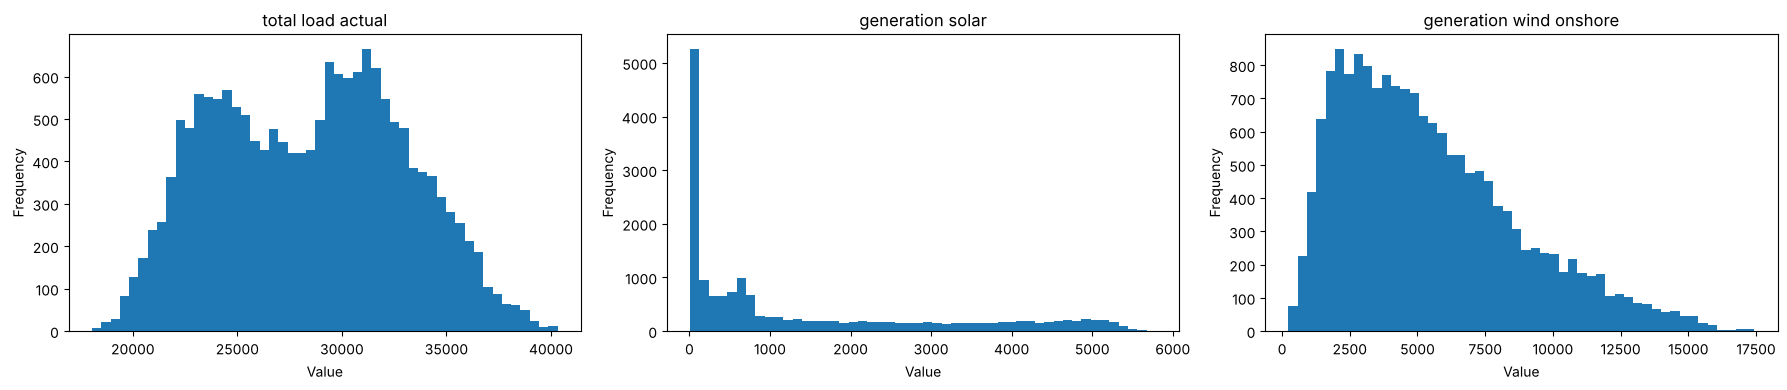

In [19]:
targets = ["total load actual","generation solar","generation wind onshore"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, target in zip(axes, targets):
    quality_col = {
        "total load actual": "usable_load",
        "generation solar": "usable_solar",
        "generation wind onshore": "usable_wind"}[target]
    data = train_data.loc[train_data[quality_col] & train_data[target].notna(),target]
    ax.hist(data, bins=50)
    ax.set_title(target)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [20]:
for target in targets:
    quality_col = {"total load actual": "usable_load","generation solar": "usable_solar",
                   "generation wind onshore": "usable_wind"}[target]
    data = train_data.loc[train_data[quality_col] & train_data[target].notna(),target]
    print(f"\n{target}")
    display(data.describe().round(2))


total load actual


count    17153.00
mean     28439.30
std       4534.62
min      18041.00
25%      24566.00
50%      28705.00
75%      31881.00
max      40324.00
Name: total load actual, dtype: float64


generation solar


count    17153.00
mean      1427.77
std       1673.16
min          9.00
25%         73.00
50%        626.00
75%       2505.00
max       5792.00
Name: generation solar, dtype: float64


generation wind onshore


count    17153.00
mean      5442.85
std       3261.46
min        234.00
25%       2849.00
50%       4801.00
75%       7382.00
max      17436.00
Name: generation wind onshore, dtype: float64

- **Load:** The distribution has multiple peaks, which may reflect different electricity consumption patterns. We should not remove these values because they may represent normal changes in electricity demand.

- **Solar:** The distribution is highly right-skewed, with many values near zero. We should not remove these values because solar generation naturally becomes low or zero when sunlight is unavailable.

- **Wind:** The distribution is right-skewed, with a few high values. We should not remove these values because they may represent periods of genuinely high wind energy generation.

## 2.3 Targets vs weather correlation

In [21]:
weather_cols = [col for col in train_data.columns
    if col.startswith(("temp_", "pressure_", "humidity_", "wind_speed_",
        "wind_deg_", "rain_", "snow_", "clouds_all_"))]

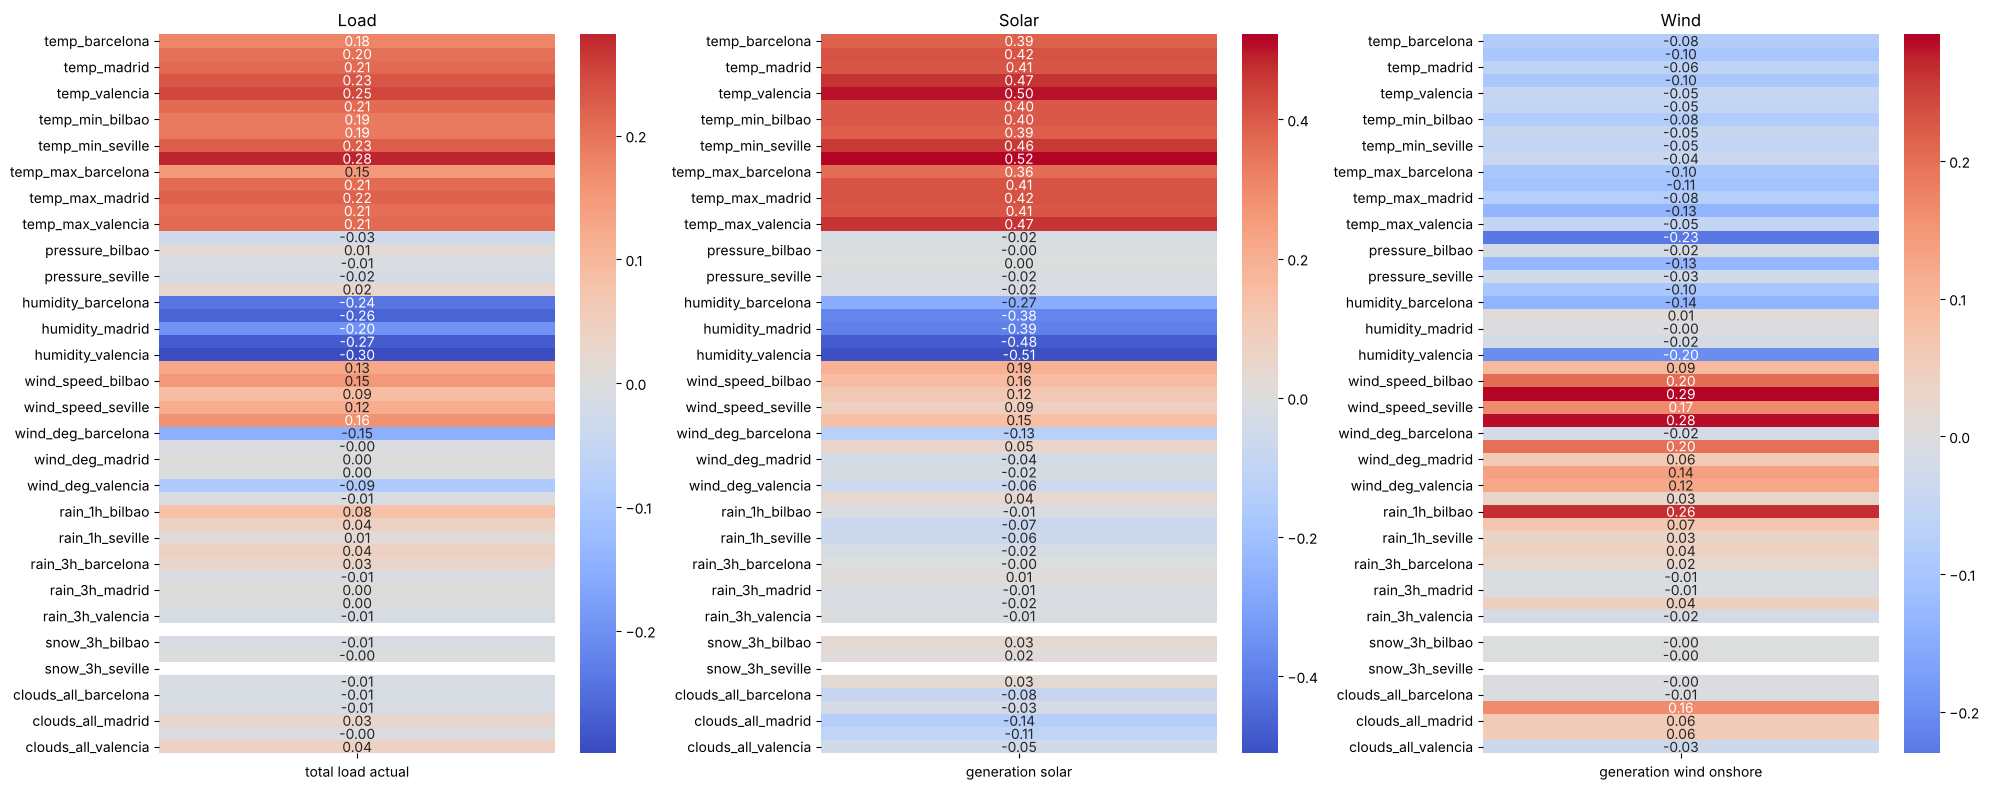

In [22]:
targets = {
    "Load": ("total load actual", "usable_load"),
    "Solar": ("generation solar", "usable_solar"),
    "Wind": ("generation wind onshore", "usable_wind")}
fig, axes = plt.subplots(1, 3, figsize=(20, 8))
for ax, (name, (target, quality)) in zip(axes, targets.items()):
    data = train_data.loc[train_data[quality] & train_data[target].notna(),
            [target] + weather_cols]
    corr = data.corr()[[target]].drop(target)
    sns.heatmap(corr, annot=True, fmt=".2f",cmap="coolwarm", center=0, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Load has a weak-to-moderate positive correlation with temperature features (about 0.15 to 0.28), meaning demand rises as temperature rises (e.g., air conditioning use).
Load has a weak negative correlation with humidity features (about -0.19 to -0.30), the strongest negative relationship in the plot.
Wind speed shows a weak positive correlation (about 0.09 to 0.16).
Pressure, wind direction, rain, snow, and clouds show near-zero correlation, so they carry little linear information about load.




Solar has the strongest correlations in the whole figure. Temperature features are strongly positive (about 0.36 to 0.51), with the maximum around 0.51.
Humidity is strongly negative (about -0.27 to -0.51), which makes sense because high humidity usually goes with clouds and less sunshine.
Wind speed has a weak positive correlation (about 0.09 to 0.19).
Clouds have a weak negative correlation (about -0.03 to -0.14), as expected since clouds block sunlight.
Pressure, rain, snow, and wind direction are close to zero.




Wind generation correlates mainly with wind speed features, with a weak-to-moderate positive correlation (up to about 0.28), which is expected physically.
Temperature features have a weak negative correlation (about -0.05 to -0.13), and humidity is weakly negative in some cities (up to about -0.20).
Some wind direction and rain features show weak positive values (e.g., rain_1h_bilbao about 0.26), which may be due to storms or weather fronts bringing both wind and rain.

## 2.4 Weather features correlation

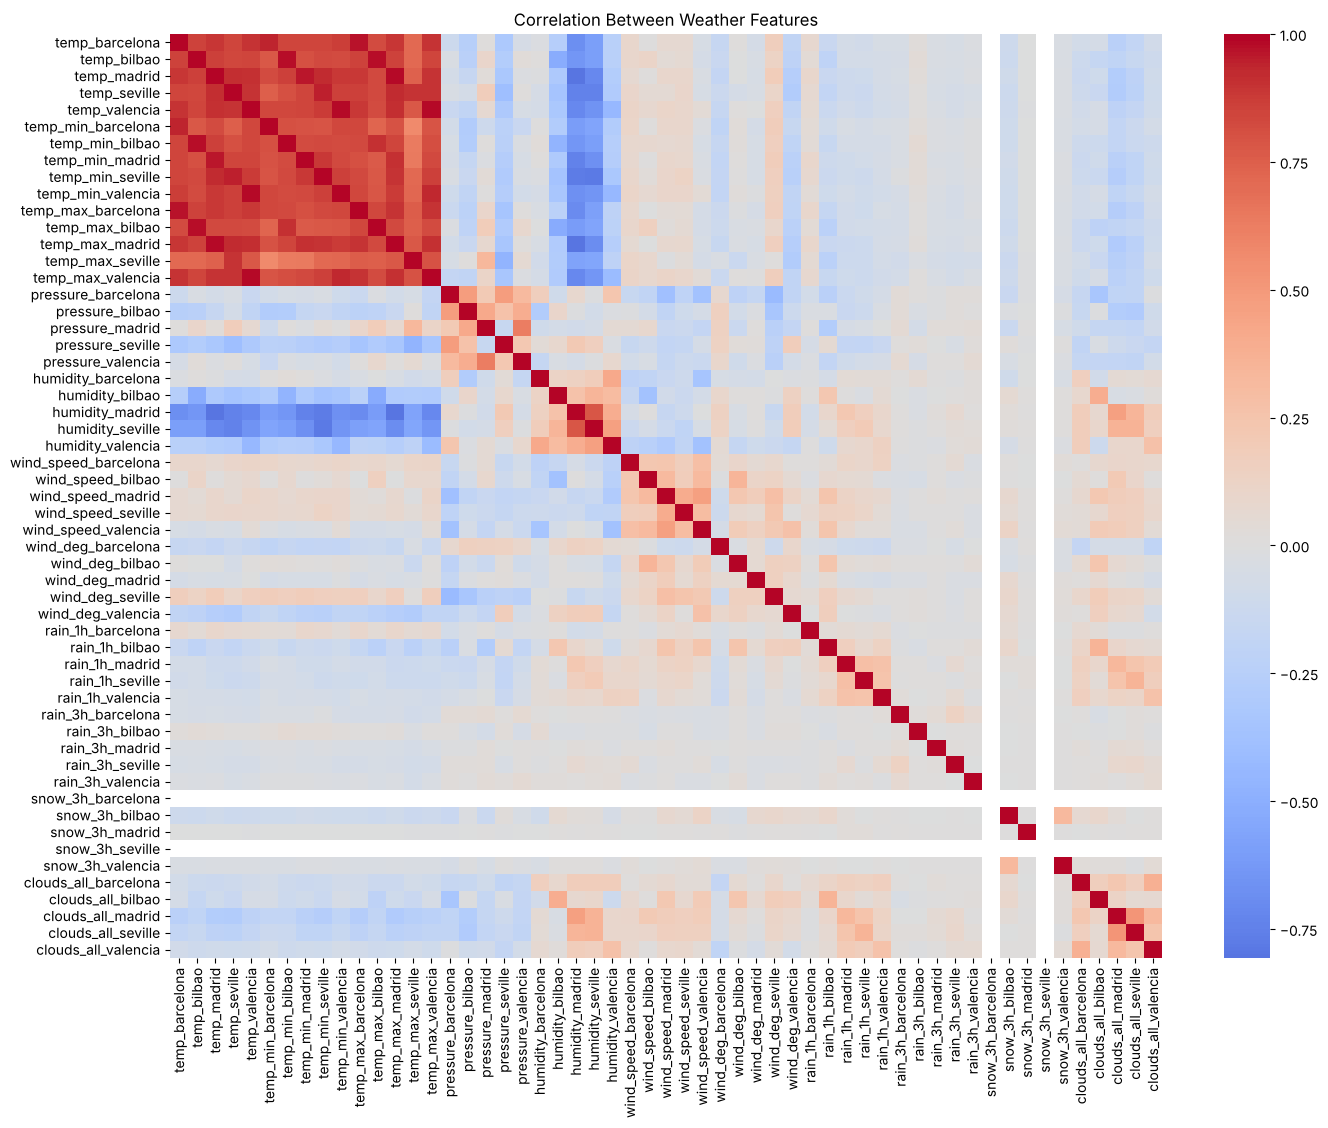

In [23]:
weather_corr = train_data[weather_cols].corr()
plt.figure(figsize=(16, 12))
sns.heatmap(weather_corr,cmap="coolwarm",center=0)

plt.title("Correlation Between Weather Features")
plt.show()

The correlation analysis revealed strong positive correlations among temperature features. The highest correlation was observed between temp_valencia and temp_max_valencia (0.984). Strong correlations were also found between temperature features across different cities, such as temp_madrid and temp_min_seville (0.930).

These results indicate that some temperature features contain overlapping information. However, no features were removed at this stage, as high correlation alone is not sufficient to determine which features should be excluded.

# Part 3 — Modelling

This section compares baseline methods and machine-learning models for three energy signals:

- **Load:** `total load actual`
- **Solar generation:** `generation solar`
- **Wind generation:** `generation wind onshore`

The models are trained using the training period, compared on the validation period, and finally evaluated on the independent test period.

The modelling workflow includes:
1. Preparing the features and targets.
2. Defining baseline methods and machine-learning models.
3. Training the models.
4. Comparing validation performance.
5. Evaluating the final models on the test set.
6. Visualizing and exporting the results.

**Forecast horizon:** the shortest lag is 48 h, so every prediction only uses data that is at least 48 hours old. Each prediction is therefore a genuine **48-hour-ahead** forecast, which meets the 24–48 h requirement.

## 3.1 Modelling Setup

We use calendar features and historical target values to predict each energy signal.

The existing time-based split boundaries are reused to identify the training, validation, and test observations. Earlier data preparation and preprocessing cells remain unchanged.

Rows with missing targets, unavailable benchmark values, or incomplete features are excluded from modelling.

In [24]:

%pip -q install lightgbm xgboost optuna mlflow shap holidays
import lightgbm as lgb

from xgboost import XGBRegressor

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Set reproducibility and feature configurations.
RANDOM_STATE = 42

LAGS = [48, 72, 168, 336]

CALENDAR_FEATURES = [
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "day_of_week",
    "is_weekend",
    "sun_elevation_deg",
]

SPLIT_NAMES = ["train", "validation", "test"]

print("Targets:", CFG["targets"])
print("Lag features:", LAGS)
print("Calendar features:", CALENDAR_FEATURES)

Note: you may need to restart the kernel to use updated packages.


Targets: {'load': 'total load actual', 'solar': 'generation solar', 'wind': 'generation wind onshore'}
Lag features: [48, 72, 168, 336]
Calendar features: ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'day_of_week', 'is_weekend', 'sun_elevation_deg']


## 3.2 Prepare the Modelling Datasets

For each energy signal:

- Apply the corresponding `usable_*` quality flag to the target.
- Create lag features from historical observations of the same signal.
- Retain the existing calendar and solar-elevation features.
- Retrieve the configured benchmark for comparison.
- Exclude rows outside the training, validation, and test periods.

The lag features use observations from earlier timestamps. They must not contain future target values.

In [25]:
# Reconstruct split labels using the existing time boundaries.
split_labels = pd.Series(
    "gap",
    index=master.index,
    dtype="object",
)

for split_name, (start, end) in bounds.items():
    mask = (
        (master.index >= start)
        & (master.index < end)
    )
    split_labels.loc[mask] = split_name

# Store the modelling data for each target.
DATA = {}

for signal, target_col in CFG["targets"].items():

    # Apply the target quality flag.
    usable_target = master[target_col].where(
        master[f"usable_{signal}"]
    )

    # Start with the existing calendar features.
    features = master[CALENDAR_FEATURES].copy()

    # Create historical lag features.
    for lag_hours in LAGS:
        features[f"lag_{lag_hours}h"] = (
            usable_target.shift(lag_hours)
        )

    # Retrieve the configured benchmark.
    benchmark = master[CFG["benchmarks"][signal]]

    # Keep rows with complete features and valid targets.
    valid_rows = (
        usable_target.notna()
        & benchmark.notna()
        & features.notna().all(axis=1)
        & split_labels.isin(SPLIT_NAMES)
    )

    DATA[signal] = {
        "X": features.loc[valid_rows],
        "y": usable_target.loc[valid_rows],
        "benchmark": benchmark.loc[valid_rows],
        "split": split_labels.loc[valid_rows],
    }

    print(f"\n{signal}")
    print(
        DATA[signal]["split"]
        .value_counts()
        .reindex(SPLIT_NAMES, fill_value=0)
    )


load
train         16745
validation     8702
test           8701
Name: count, dtype: int64

solar
train         16730
validation     8635
test           8594
Name: count, dtype: int64

wind
train         16833
validation     8712
test           8706
Name: count, dtype: int64


## 3.3 Define Baselines and Machine-Learning Models

Two baseline predictions are included:

- **Weekly Naive (`naive_168h`):** uses the target value from 168 hours earlier.
- **Operational Benchmark (`tso_day_ahead`):** uses the benchmark column configured in the earlier notebook cells.

The machine-learning models cover several model families:

- Linear models: Ridge and ElasticNet.
- Tree ensembles: Random Forest and Extra Trees.
- Gradient boosting: HistGradientBoosting, LightGBM, and XGBoost.
- Neural network: Multi-Layer Perceptron (MLP).

Feature scaling is used for models that benefit from standardized input values.

In [26]:
# Define evaluation metrics.
def mean_absolute_error(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return float(
        np.mean(np.abs(y_true - y_pred))
    )


def normalized_mae_percent(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mean_target = float(np.mean(y_true))

    if np.isclose(mean_target, 0):
        return np.nan

    return (
        100
        * mean_absolute_error(y_true, y_pred)
        / mean_target
    )


def make_models():

    return {
        "ridge": make_pipeline(
            StandardScaler(),
            Ridge(alpha=10),
        ),

        "elasticnet": make_pipeline(
            StandardScaler(),
            ElasticNet(
                alpha=0.1,
                l1_ratio=0.5,
                max_iter=5000,
            ),
        ),

        "random_forest": RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),

        "extra_trees": ExtraTreesRegressor(
            n_estimators=200,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),

        "hist_gb": HistGradientBoostingRegressor(
            loss="absolute_error",
            max_iter=300,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
        ),

        "lightgbm": lgb.LGBMRegressor(
            objective="regression_l1",
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=50,
            random_state=RANDOM_STATE,
            verbosity=-1,
        ),

        "xgboost": XGBRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:absoluteerror",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        ),

        "mlp": TransformedTargetRegressor(
            regressor=make_pipeline(
                StandardScaler(),
                MLPRegressor(
                    hidden_layer_sizes=(64, 32),
                    max_iter=100,
                    random_state=RANDOM_STATE,
                ),
            ),
            transformer=StandardScaler(),
        ),
    }


MODEL_ORDER = [
    "naive_168h",
    "tso_day_ahead",
    "ridge",
    "elasticnet",
    "random_forest",
    "extra_trees",
    "hist_gb",
    "lightgbm",
    "xgboost",
    "mlp",
    "ensemble_avg",
]

In [27]:

PREDICTIONS = {}

FITTED = {}   # fitted models per signal

for signal, dataset in DATA.items():
    models = make_models()   # FIX: a fresh set per signal (one shared set ended up holding the wind fit)
    FITTED[signal] = models

    train_mask = dataset["split"].eq("train")

    X_all = dataset["X"]
    y_train = dataset["y"].loc[train_mask]

    predictions = {
        "naive_168h": X_all["lag_168h"].copy(),
        "tso_day_ahead": dataset["benchmark"].copy(),
    }

    for model_name, model in models.items():

        model.fit(
            X_all.loc[train_mask],
            y_train,
        )

        predictions[model_name] = pd.Series(
            model.predict(X_all),
            index=X_all.index,
            name=model_name,
        )

        print(f"{signal}: trained {model_name}")

    # Calculate the average ensemble prediction.
    predictions["ensemble_avg"] = (
        predictions["lightgbm"]
        + predictions["xgboost"]
        + predictions["mlp"]
    ) / 3

    PREDICTIONS[signal] = predictions

print("Model training and prediction generation completed.")

load: trained ridge
load: trained elasticnet


load: trained random_forest


load: trained extra_trees


load: trained hist_gb


load: trained lightgbm


...

wind: trained hist_gb


wind: trained lightgbm


wind: trained xgboost


wind: trained mlp
Model training and prediction generation completed.


/usr/local/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


## 3.4 Validation Results

The validation set is used to compare model performance before the final test evaluation.

We report:

- **MAE (Mean Absolute Error):** the average absolute prediction error in the target's original units.
- **nMAE (Normalized MAE):** MAE expressed as a percentage of the mean actual target value.

Lower values indicate better performance for both metrics.

The validation results should guide model comparison without using the test set to select models.

In [28]:
# Calculate metrics for a selected data split.
def build_metrics_table(split_name):

    records = []

    for signal, dataset in DATA.items():

        mask = dataset["split"].eq(split_name)
        y_true = dataset["y"].loc[mask]

        for model_name, prediction in PREDICTIONS[signal].items():

            y_pred = prediction.loc[mask]

            records.append({
                "model": model_name,
                "signal": signal,
                "split": split_name,
                "MAE": mean_absolute_error(
                    y_true,
                    y_pred,
                ),
                "nMAE_pct": normalized_mae_percent(
                    y_true,
                    y_pred,
                ),
            })

    return pd.DataFrame(records)


# Evaluate the models on the validation split.
validation_results = build_metrics_table("validation")

print("Validation MAE")
display(
    validation_results.pivot(
        index="model",
        columns="signal",
        values="MAE",
    )
    .reindex(MODEL_ORDER)
    .round(2)
)

print("Validation nMAE (%)")
display(
    validation_results.pivot(
        index="model",
        columns="signal",
        values="nMAE_pct",
    )
    .reindex(MODEL_ORDER)
    .round(2)
)

Validation MAE


signal,load,solar,wind
model,,,
naive_168h,2631.16,756.60,3227.77
tso_day_ahead,314.25,102.65,99.46
ridge,2245.37,565.85,2346.14
elasticnet,2252.00,572.51,2348.84
random_forest,1973.61,490.09,2584.23
extra_trees,1918.53,488.30,2611.42
hist_gb,1877.47,479.51,2490.28
lightgbm,1871.99,482.12,2540.46
xgboost,1879.33,481.56,2575.18


Validation nMAE (%)


signal,load,solar,wind
model,,,
naive_168h,9.12,50.34,59.93
tso_day_ahead,1.09,6.83,1.85
ridge,7.78,37.65,43.56
elasticnet,7.80,38.09,43.61
random_forest,6.84,32.61,47.98
extra_trees,6.65,32.49,48.49
hist_gb,6.51,31.90,46.24
lightgbm,6.49,32.08,47.17
xgboost,6.51,32.04,47.81


## 3.4b Hyper-parameter tuning with Optuna (new)
LightGBM is tuned per signal with Optuna (TPE sampler, 30 trials). Each trial is scored on **three time-ordered folds inside the training period** (Apr-Jun, Jul-Sep, Oct-Dec 2016; each fold trains only on data that ends 48 h before it starts). The validation year stays untouched, so the tuned model competes with the others on validation like any other model. Trial 0 is the team's original LightGBM configuration.

In [29]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 30
CV_FOLDS = [("2016-04-01", "2016-07-01"), ("2016-07-01", "2016-10-01"), ("2016-10-01", "2017-01-01")]
GAP = pd.Timedelta(hours=CFG["gap_hours"])
TEAM_LGBM = {"n_estimators": 500, "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 50,
             "subsample": 1.0, "colsample_bytree": 1.0, "reg_lambda": 1e-3}

def cv_folds(index):
    folds = []
    for a, b in CV_FOLDS:
        a, b = pd.Timestamp(a, tz="UTC"), pd.Timestamp(b, tz="UTC")
        folds.append((np.where(index < a - GAP)[0], np.where((index >= a) & (index < b))[0]))
    return folds

def lgbm_params(p):
    return dict(objective="regression_l1", subsample_freq=1, random_state=RANDOM_STATE, verbosity=-1, **p)

def make_objective(X, y, folds):
    def objective(trial):
        p = {"n_estimators": trial.suggest_int("n_estimators", 200, 1500, step=100),
             "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
             "num_leaves": trial.suggest_int("num_leaves", 15, 127),
             "min_child_samples": trial.suggest_int("min_child_samples", 20, 300),
             "subsample": trial.suggest_float("subsample", 0.6, 1.0),
             "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
             "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True)}
        maes = [mean_absolute_error(y.iloc[va], lgb.LGBMRegressor(**lgbm_params(p)).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va]))
                for tr, va in folds]
        trial.set_user_attr("fold_mae", [round(m, 1) for m in maes])
        return float(np.mean(maes))
    return objective

TUNING = {}
for signal, dataset in DATA.items():
    tr = dataset["split"].eq("train")
    X, y = dataset["X"].loc[tr], dataset["y"].loc[tr]
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
                                study_name=f"lgbm_{signal}")
    study.enqueue_trial(TEAM_LGBM)                                     # trial 0 = team configuration
    study.optimize(make_objective(X, y, cv_folds(X.index)), n_trials=N_TRIALS)
    params = lgbm_params(study.best_params)
    model = lgb.LGBMRegressor(**params).fit(X, y)                      # refit on the whole training period
    FITTED[signal]["lightgbm_tuned"] = model
    PREDICTIONS[signal]["lightgbm_tuned"] = pd.Series(model.predict(dataset["X"]), index=dataset["X"].index, name="lightgbm_tuned")
    TUNING[signal] = {"study": study, "params": params,
                      "team_cv_mae": study.trials[0].value, "best_cv_mae": study.best_value}
    print(f"{signal}: CV MAE team config {study.trials[0].value:8.1f} -> tuned {study.best_value:8.1f} MW "
          f"(folds {study.best_trial.user_attrs['fold_mae']})")

if "lightgbm_tuned" not in MODEL_ORDER:
    MODEL_ORDER.insert(MODEL_ORDER.index("lightgbm") + 1, "lightgbm_tuned")
validation_results = build_metrics_table("validation")
print("\nValidation MAE including the tuned model")
display(validation_results.pivot(index="model", columns="signal", values="MAE").reindex(MODEL_ORDER).round(2))

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


load: CV MAE team config   1659.0 -> tuned   1614.8 MW (folds [1608.1, 1618.8, 1617.4])


solar: CV MAE team config    545.6 -> tuned    519.4 MW (folds [582.1, 525.7, 450.4])


wind: CV MAE team config   2581.0 -> tuned   2411.3 MW (folds [2411.6, 2315.1, 2507.1])

Validation MAE including the tuned model


signal,load,solar,wind
model,,,
naive_168h,2631.16,756.60,3227.77
tso_day_ahead,314.25,102.65,99.46
ridge,2245.37,565.85,2346.14
elasticnet,2252.00,572.51,2348.84
random_forest,1973.61,490.09,2584.23
extra_trees,1918.53,488.30,2611.42
hist_gb,1877.47,479.51,2490.28
lightgbm,1871.99,482.12,2540.46
lightgbm_tuned,1845.34,474.23,2367.74


## 3.5 Final Test Evaluation

The test period provides the final performance comparison on data that was not used to fit the models.

We calculate:

- **MAE:** average absolute error.
- **RMSE:** penalizes larger errors more strongly.
- **nMAE:** error relative to the mean actual target.
- **R²:** measures performance relative to predicting the mean target; it can be negative.

We also calculate the percentage improvement in MAE relative to the weekly naive baseline. Positive improvement means lower MAE than the baseline.

In [30]:
# Calculate the final test metrics.
def build_test_results():

    records = []

    for signal, dataset in DATA.items():

        test_mask = dataset["split"].eq("test")
        y_true = dataset["y"].loc[test_mask]

        for model_name, prediction in PREDICTIONS[signal].items():

            y_pred = prediction.loc[test_mask]
            errors = y_pred - y_true

            denominator = float(
                np.square(y_true - y_true.mean()).sum()
            )

            records.append({
                "model": model_name,
                "signal": signal,
                "MAE": float(np.abs(errors).mean()),
                "RMSE": float(
                    np.sqrt(np.square(errors).mean())
                ),
                "nMAE_pct": normalized_mae_percent(
                    y_true,
                    y_pred,
                ),
                "R2": (
                    float(
                        1
                        - np.square(errors).sum()
                        / denominator
                    )
                    if denominator > 0
                    else np.nan
                ),
            })

    return pd.DataFrame(records)


# Generate and export the test results.
test_results = build_test_results()

test_results.to_csv(
    OUT / "test_results_all_models.csv",
    index=False,
)


# Create consistent comparison tables.
def test_metric_table(metric, digits=2):

    return (
        test_results.pivot(
            index="model",
            columns="signal",
            values=metric,
        )
        .reindex(MODEL_ORDER)
        .round(digits)
    )


print("Test MAE")
display(test_metric_table("MAE", 2))

print("Test nMAE (%)")
display(test_metric_table("nMAE_pct", 2))

print("Test RMSE")
display(test_metric_table("RMSE", 2))

print("Test R²")
display(test_metric_table("R2", 3))

test_mae = test_metric_table("MAE", 2)
baseline_mae = test_mae.loc["naive_168h"]

improvement = 100 * (
    1 - test_mae.div(baseline_mae)
)

print("MAE improvement over naive baseline (%)")
display(improvement.round(2))

average_rank = (
    test_mae.rank(axis=0, method="average")
    .mean(axis=1)
    .sort_values()
)

print("Average MAE rank across signals (lower is better)")
display(
    average_rank.to_frame("average_rank").round(2)
)

Test MAE


signal,load,solar,wind
model,,,
naive_168h,2640.89,725.52,3427.42
tso_day_ahead,268.62,141.27,448.27
ridge,2254.16,556.30,2522.94
elasticnet,2264.08,563.02,2525.32
random_forest,1964.73,510.32,2763.45
extra_trees,1910.79,496.52,2737.25
hist_gb,1859.45,493.66,2650.96
lightgbm,1854.50,496.37,2714.65
lightgbm_tuned,1810.57,478.87,2558.37


Test nMAE (%)


signal,load,solar,wind
model,,,
naive_168h,9.09,52.63,61.54
tso_day_ahead,0.92,10.25,8.05
ridge,7.75,40.35,45.30
elasticnet,7.79,40.84,45.35
random_forest,6.76,37.02,49.62
extra_trees,6.57,36.02,49.15
hist_gb,6.40,35.81,47.60
lightgbm,6.38,36.00,48.75
lightgbm_tuned,6.23,34.74,45.94


Test RMSE


...

signal,load,solar,wind
model,,,
naive_168h,0.318,0.485,-0.737
tso_day_ahead,0.993,0.981,0.965
ridge,0.576,0.755,0.112
elasticnet,0.575,0.755,0.112
random_forest,0.642,0.769,-0.130
extra_trees,0.658,0.783,-0.097
hist_gb,0.650,0.759,-0.066
lightgbm,0.648,0.754,-0.110
lightgbm_tuned,0.664,0.767,0.024


MAE improvement over naive baseline (%)


signal,load,solar,wind
model,,,
naive_168h,0.00,0.00,0.00
tso_day_ahead,89.83,80.53,86.92
ridge,14.64,23.32,26.39
elasticnet,14.27,22.40,26.32
random_forest,25.60,29.66,19.37
extra_trees,27.65,31.56,20.14
hist_gb,29.59,31.96,22.65
lightgbm,29.78,31.58,20.80
lightgbm_tuned,31.44,34.00,25.36


Average MAE rank across signals (lower is better)


,average_rank
model,
tso_day_ahead,1.00
lightgbm_tuned,2.67
hist_gb,4.00
lightgbm,4.33
xgboost,6.33
extra_trees,6.67
ridge,7.00
ensemble_avg,7.33
elasticnet,8.00


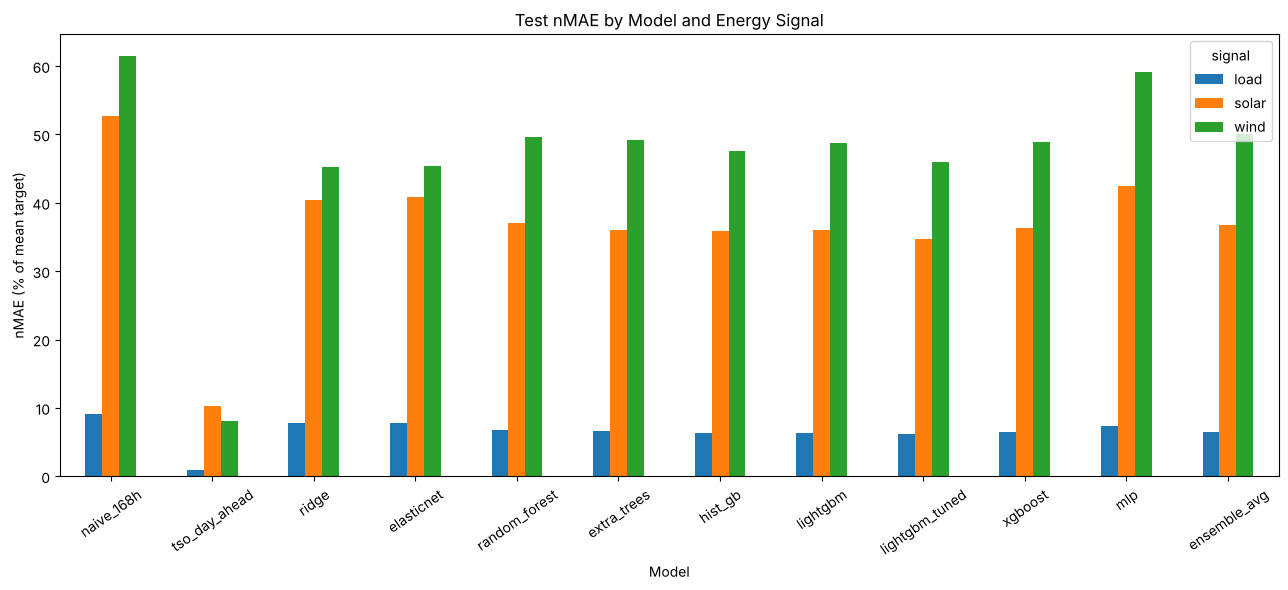

Saved test metrics to: /content/gridpulse_outputs/test_results_all_models.csv


In [31]:
test_nmae = test_metric_table("nMAE_pct", 2)

ax = test_nmae.plot(
    kind="bar",
    figsize=(13, 6),
    title="Test nMAE by Model and Energy Signal",
)

ax.set_xlabel("Model")
ax.set_ylabel("nMAE (% of mean target)")
ax.tick_params(
    axis="x",
    rotation=35,
)

plt.tight_layout()
plt.show()

print(
    "Saved test metrics to:",
    OUT / "test_results_all_models.csv",
)

## 3.6 Production model per signal — chosen on validation (new)
The test year is only used to report. The production model is the one with the lowest **validation** MAE among the models we can serve with exact per-prediction explanations and version-safe files: Ridge, ElasticNet, LightGBM (default or tuned) and XGBoost. Random Forest, Extra Trees, HistGradientBoosting, MLP and the average ensemble stay in the comparison; the table shows how far the best of them is.

In [32]:
PRODUCTION_CANDIDATES = ["ridge", "elasticnet", "lightgbm", "lightgbm_tuned", "xgboost"]
val_mae = validation_results.pivot(index="model", columns="signal", values="MAE")
tst = test_results.set_index(["signal", "model"])
PRODUCTION = {s: val_mae.loc[PRODUCTION_CANDIDATES, s].idxmin() for s in CFG["targets"]}

rows = []
for s, name in PRODUCTION.items():
    best_any = val_mae.drop(index=["naive_168h", "tso_day_ahead"])[s].idxmin()
    rows.append({
        "signal": s, "production_model": name,
        "validation_MAE": val_mae.loc[name, s],
        "best_model_any": best_any, "best_any_validation_MAE": val_mae.loc[best_any, s],
        "gap_to_best_pct": 100 * (val_mae.loc[name, s] / val_mae.loc[best_any, s] - 1),
        "test_MAE": tst.loc[(s, name), "MAE"], "test_nMAE_pct": tst.loc[(s, name), "nMAE_pct"],
        "test_R2": tst.loc[(s, name), "R2"],
        "naive_test_MAE": tst.loc[(s, "naive_168h"), "MAE"], "tso_test_MAE": tst.loc[(s, "tso_day_ahead"), "MAE"],
    })
production_summary = pd.DataFrame(rows).set_index("signal")
production_summary["improvement_vs_naive_pct"] = 100 * (1 - production_summary["test_MAE"] / production_summary["naive_test_MAE"])
production_summary.to_csv(OUT / "production_models.csv")
display(production_summary.round(2))

,production_model,validation_MAE,best_model_any,best_any_validation_MAE,gap_to_best_pct,test_MAE,test_nMAE_pct,test_R2,naive_test_MAE,tso_test_MAE,improvement_vs_naive_pct
signal,,,,,,,,,,,
load,lightgbm_tuned,1845.34,lightgbm_tuned,1845.34,0.0,1810.57,6.23,0.66,2640.89,268.62,31.44
solar,lightgbm_tuned,474.23,lightgbm_tuned,474.23,0.0,478.87,34.74,0.77,725.52,141.27,34.00
wind,ridge,2346.14,ridge,2346.14,0.0,2522.94,45.30,0.11,3427.42,448.27,26.39


## 3.7 Experiment tracking with MLflow (new)
Everything is logged to a local MLflow store in `OUT` (`mlflow.db` + `mlartifacts/`): one run per (signal, model) with parameters and validation/test metrics, one run per Optuna study with all trials, and one run per production model, which is also registered in the **MLflow Model Registry** as `gridpulse-forecast-<signal>`. Open it with `mlflow ui --backend-store-uri sqlite:///<OUT>/mlflow.db`.

In [33]:
import mlflow, mlflow.sklearn, mlflow.lightgbm, mlflow.xgboost, warnings, platform
warnings.filterwarnings("ignore", module="mlflow")

mlflow.set_tracking_uri(f"sqlite:///{OUT / 'mlflow.db'}")
EXPERIMENT = "gridpulse_team22"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(OUT / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENT)

FAMILY = {"naive_168h": "baseline", "tso_day_ahead": "benchmark", "ridge": "linear", "elasticnet": "linear",
          "random_forest": "tree_ensemble", "extra_trees": "tree_ensemble", "hist_gb": "gradient_boosting",
          "lightgbm": "gradient_boosting", "lightgbm_tuned": "gradient_boosting", "xgboost": "gradient_boosting",
          "mlp": "neural_network", "ensemble_avg": "ensemble"}

def simple_params(est):
    return {k: v for k, v in est.get_params().items() if isinstance(v, (int, float, str, bool)) and len(str(v)) < 250}

val_l, tst_l = validation_results.set_index(["signal", "model"]), test_results.set_index(["signal", "model"])
common = {"dataset_version": DATASET_VERSION, "lags_h": str(LAGS), "calendar_features": ",".join(CALENDAR_FEATURES)}
for signal in CFG["targets"]:
    for name in PREDICTIONS[signal]:
        est = FITTED[signal].get(name)
        with mlflow.start_run(run_name=f"{signal}__{name}"):
            mlflow.set_tags({"signal": signal, "model": name, "family": FAMILY[name],
                             "production": str(PRODUCTION[signal] == name)})
            mlflow.log_params({**common, **(simple_params(est) if est is not None else {"kind": FAMILY[name]})})
            mlflow.log_metrics({"val_MAE": val_l.loc[(signal, name), "MAE"], "val_nMAE_pct": val_l.loc[(signal, name), "nMAE_pct"],
                                **{f"test_{m}": tst_l.loc[(signal, name), m] for m in ["MAE", "RMSE", "nMAE_pct", "R2"]}})

for signal, t in TUNING.items():
    trials = t["study"].trials_dataframe()
    trials.to_csv(OUT / f"optuna_trials_{signal}.csv", index=False)
    with mlflow.start_run(run_name=f"optuna__{signal}"):
        mlflow.set_tags({"signal": signal, "model": "lightgbm_tuned", "family": "tuning"})
        mlflow.log_params({**common, "n_trials": N_TRIALS, "cv_folds": str(CV_FOLDS), **t["study"].best_params})
        mlflow.log_metrics({"team_config_cv_MAE": t["team_cv_mae"], "best_cv_MAE": t["best_cv_mae"]})
        mlflow.log_artifact(str(OUT / f"optuna_trials_{signal}.csv"))

for signal, name in PRODUCTION.items():
    X = DATA[signal]["X"]
    with mlflow.start_run(run_name=f"production__{signal}"):
        mlflow.set_tags({"signal": signal, "model": name, "family": FAMILY[name], "stage": "production"})
        mlflow.log_params({**common, "model": name, "selected_on": "validation MAE"})
        mlflow.log_metrics({f"test_{m}": tst_l.loc[(signal, name), m] for m in ["MAE", "RMSE", "nMAE_pct", "R2"]}
                           | {"val_MAE": val_l.loc[(signal, name), "MAE"]})
        log_model = (mlflow.lightgbm.log_model if name.startswith("lightgbm") else
                     mlflow.xgboost.log_model if name == "xgboost" else
                     lambda m, **kw: mlflow.sklearn.log_model(m, serialization_format="cloudpickle", **kw))
        log_model(FITTED[signal][name], name="model", input_example=X.head(3),
                  registered_model_name=f"gridpulse-forecast-{signal}")

runs = mlflow.search_runs(experiment_names=[EXPERIMENT])
print(f"MLflow: {len(runs)} runs in '{EXPERIMENT}'; registered models:",
      [m.name for m in mlflow.MlflowClient().search_registered_models()])

2026/10/27 01:47:31 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /usr/local/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026/10/27 01:47:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/27 01:47:32 INFO mlflow.store.db.utils: Updating database tables


Successfully registered model 'gridpulse-forecast-load'.
Created version '1' of model 'gridpulse-forecast-load'.


Successfully registered model 'gridpulse-forecast-solar'.
Created version '1' of model 'gridpulse-forecast-solar'.
2026/10/27 01:47:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


MLflow: 42 runs in 'gridpulse_team22'; registered models: ['gridpulse-forecast-load', 'gridpulse-forecast-solar', 'gridpulse-forecast-wind']


Successfully registered model 'gridpulse-forecast-wind'.
Created version '1' of model 'gridpulse-forecast-wind'.


## 3.8 Explanations with SHAP (new)
For the production models SHAP values are exact and cheap: TreeSHAP for LightGBM/XGBoost (computed natively by the library) and coefficient × standardised value for Ridge/ElasticNet. For every forecast, `base value + sum of contributions = forecast`, which the API returns for each prediction. The beeswarm shows which inputs drive the forecasts over the test year; the waterfall explains the single test hour with the largest error.

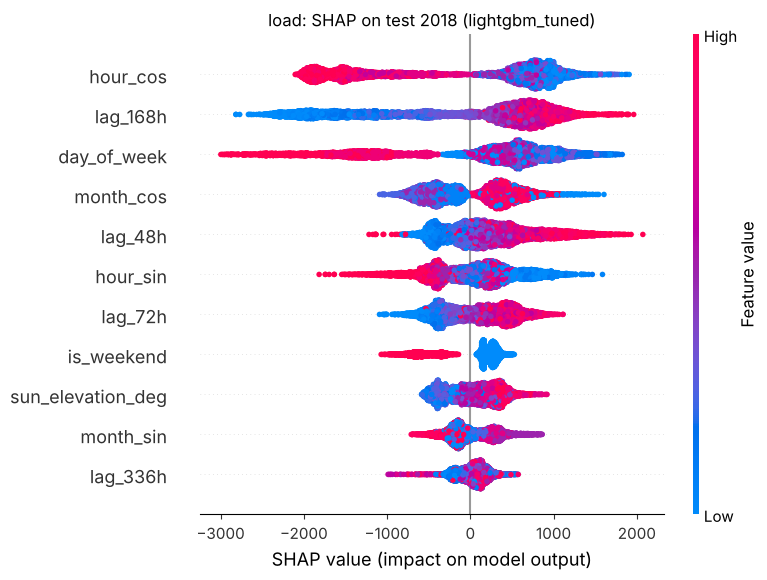

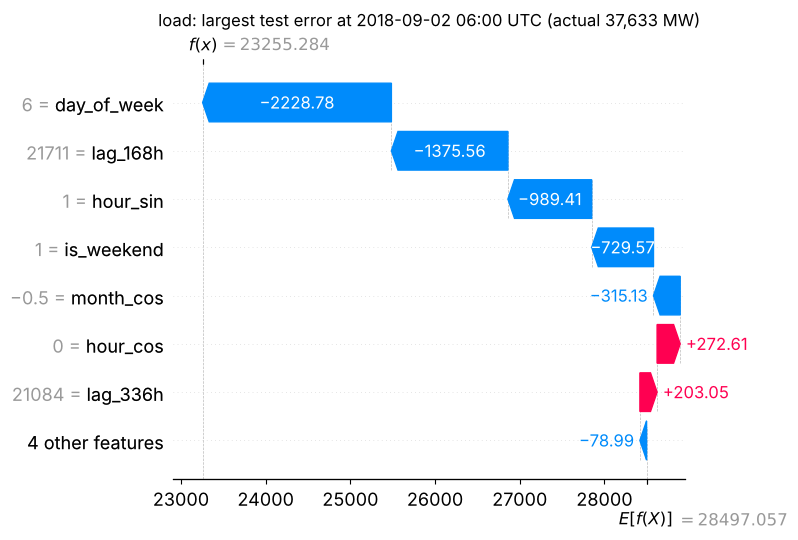

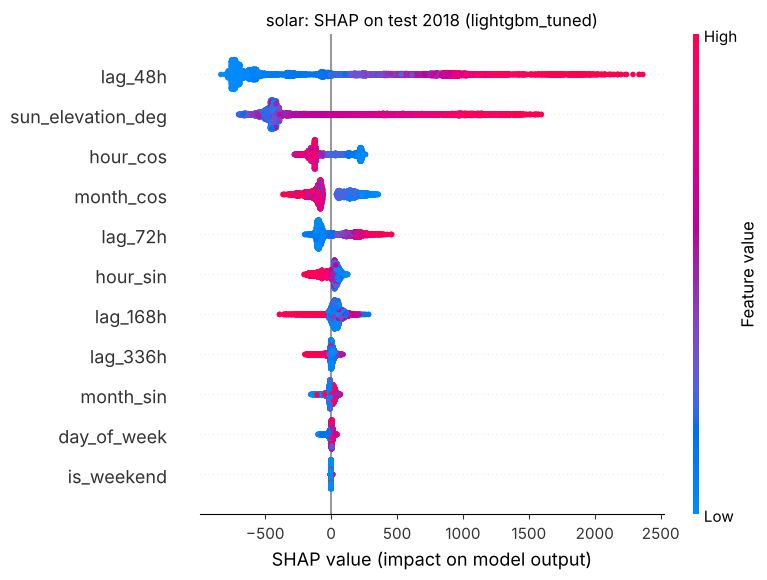

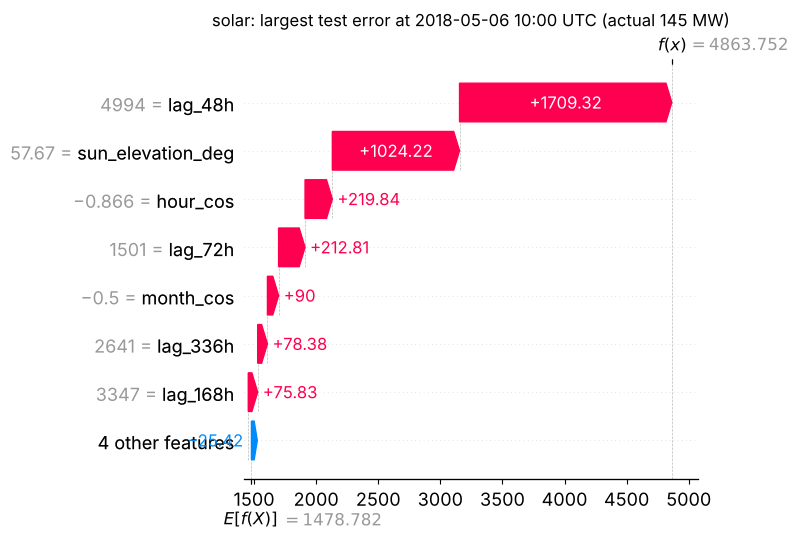

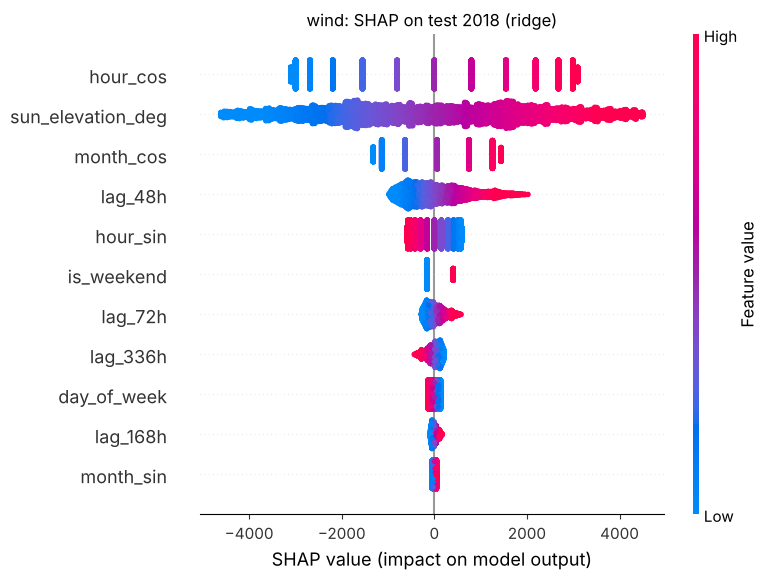

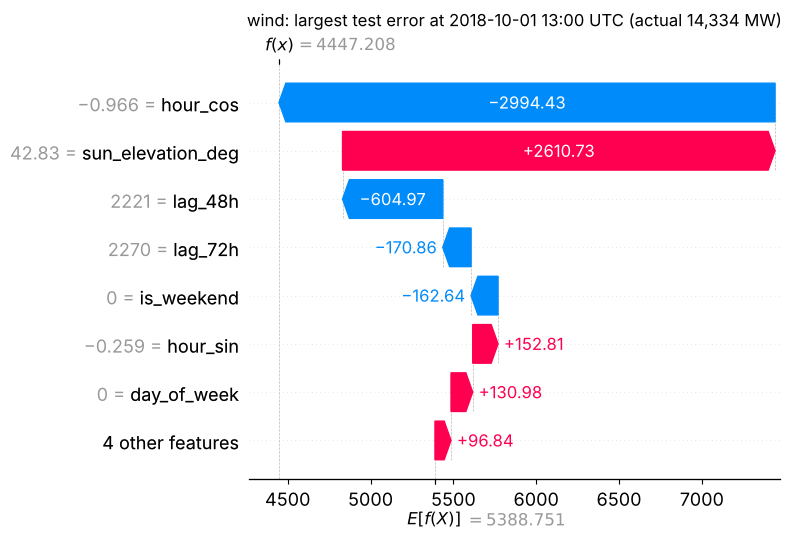

Mean |SHAP| on test (MW): the larger, the more the feature moves the forecast


,load,solar,wind
day_of_week,853.8,11.9,74.7
hour_cos,1044.8,151.7,1961.8
hour_sin,406.9,54.0,373.9
is_weekend,329.8,1.0,232.4
lag_168h,913.0,53.1,45.1
lag_336h,137.4,23.9,112.4
lag_48h,427.8,675.5,513.9
lag_72h,357.7,115.8,147.8
month_cos,429.7,138.8,864.6
month_sin,223.5,21.7,31.2


In [34]:
import shap, xgboost as xgb

def contributions(signal, X):
    """Exact per-feature contributions (MW) and base value for the production model of a signal."""
    name, est = PRODUCTION[signal], FITTED[signal][PRODUCTION[signal]]
    if name.startswith("lightgbm"):
        c = est.booster_.predict(X, pred_contrib=True)
        values, base = c[:, :-1], c[:, -1]
    elif name == "xgboost":
        c = est.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
        values, base = c[:, :-1], c[:, -1]
    else:                                                     # StandardScaler + linear model
        scaler, linear = est[0], est[-1]
        values = (X.to_numpy(float) - scaler.mean_) / scaler.scale_ * linear.coef_
        base = np.full(len(X), float(linear.intercept_))
    assert np.allclose(values.sum(axis=1) + base, est.predict(X), atol=1e-2), "contributions must add up to the forecast"
    return values, base

shap_global = {}
for signal in CFG["targets"]:
    d = DATA[signal]
    mask = d["split"].eq("test")
    X_test, y_test = d["X"].loc[mask], d["y"].loc[mask]
    values, base = contributions(signal, X_test)
    expl = shap.Explanation(values=values, base_values=base, data=X_test.to_numpy(float), feature_names=list(X_test.columns))
    shap_global[signal] = pd.Series(np.abs(values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)

    plt.figure()
    shap.plots.beeswarm(expl, max_display=11, show=False)
    plt.title(f"{signal}: SHAP on test 2018 ({PRODUCTION[signal]})")
    plt.tight_layout(); plt.show()

    i = int(np.argmax(np.abs(PREDICTIONS[signal][PRODUCTION[signal]].loc[mask].to_numpy() - y_test.to_numpy())))
    plt.figure()
    shap.plots.waterfall(expl[i], max_display=8, show=False)
    plt.title(f"{signal}: largest test error at {X_test.index[i]:%Y-%m-%d %H:00} UTC (actual {y_test.iloc[i]:,.0f} MW)")
    plt.tight_layout(); plt.show()

shap_table = pd.DataFrame(shap_global).round(1)
shap_table.to_csv(OUT / "shap_mean_abs_test.csv")
print("Mean |SHAP| on test (MW): the larger, the more the feature moves the forecast")
display(shap_table)

### Conclusion of Part 3 (updated: the model is chosen on validation, not on test)
- **Production models (3.6):** tuned LightGBM for **load** and **solar**, Ridge for **wind**. Each is also the best of all compared models on validation, so restricting the choice to explainable, version-safe models costs nothing here.
- **Optuna (3.4b)** lowered the cross-validated MAE of LightGBM on every signal (load 1,659 → 1,615 MW, solar 546 → 519 MW, wind 2,581 → 2,411 MW). On wind, Ridge still wins on validation.
- **Test 2018, 48 h ahead:** load 1,811 MW MAE (6.2 % nMAE), solar 479 MW (34.7 %), wind 2,523 MW (45.3 %). That is **31 %, 34 % and 26 % lower error than the naive "same hour last week"** forecast.
- **Honest limit:** the operator's day-ahead forecast (TSO) stays far better (269 / 141 / 448 MW) because it uses weather forecasts that this dataset does not contain. Our model is an independent forecast and the expectation behind the anomaly alerts, not a replacement for the operator forecast.
- Wind is the hardest signal (R² close to 0): 48 h ahead, without wind-speed forecasts at the wind farms, only calendar patterns and the recent level are available.

# Part 4 — Anomaly detection

**Goal:** flag hours where load, solar or wind behave abnormally, so a dispatcher can review them. Abnormal can mean a data error (sensor frozen, value missing, solar output at night) or an operational event (plant trip, sudden drop or spike).

**Three checks per signal, hourly:**
1. **Data-quality rules**: the trust layer from 1.5 (missing, out of range, flatline, solar at night, midday zero, load far from the last 4 weeks), packaged as a reusable function.
2. **Nowcast band**: the expected value of hour *t* from what is known when hour *t* is checked: values up to *t-1*, weather measured at *t*, calendar and sun elevation. It is tight, so sudden faults stand out.
3. **Forecast band**: the actual value against the 48-h-ahead forecast of the production model from 3.6. It is wide, but it does not adapt to a fault that lasts.

Bands are set per local hour so that 1 % of validation hours fall outside each band. **Alert policy = data-error rule OR nowcast band OR forecast band.** An Isolation Forest on the same residuals is reported as a comparison method.

**No test leakage:** the nowcast and forecast models are fitted on train; bands and the Isolation Forest are calibrated on validation (2017) and applied unchanged to test (2018).

**Evidence, because no fault labels exist:** every 2018 alert is cross-checked against the trust layer, other signals alerting at the same time, public holidays and the operator forecast; synthetic faults are injected into 2018 to measure what is caught and how fast.

## 4.1 Setup: trust rules as a function, raw targets, forecast model

In [35]:
import holidays
from sklearn.ensemble import IsolationForest

LOCAL_TZ = "Europe/Madrid"
CITIES = ["barcelona", "bilbao", "madrid", "seville", "valencia"]
ANOM = {
    "alert_budget": 0.01,                                    # share of validation hours allowed outside each band
    "min_half_width_mw": {"load": 500, "solar": 100, "wind": 300},
    "merge_gap_h": 1,                                        # flagged hours at most this far apart form one event
    "iforest": {"n_estimators": 300, "contamination": 0.01, "random_state": RANDOM_STATE},
    "critical": {"min_hours": 3, "min_ratio": 1.5},          # CRITICAL = long AND far outside the band
}
ANOM_DIR = OUT / "anomaly"
ANOM_DIR.mkdir(exist_ok=True)
es_holidays = holidays.Spain(years=range(2014, 2020))

# Raw targets and operator forecasts straight from the CSV, on the full hourly grid (35,064 h):
# Part 4 must see every gap, and the 4-week load rule needs the first weeks that 1.8 removes from `master`.
RAW = (energy_raw.assign(time_utc=pd.to_datetime(energy_raw["time"], utc=True)).set_index("time_utc").sort_index()
       [list(CFG["targets"].values()) + list(CFG["benchmarks"].values())])
SPLIT_FULL = pd.Series("gap", index=RAW.index)
for name_, (a, b) in bounds.items():
    SPLIT_FULL[(RAW.index >= a) & (RAW.index < b)] = name_
TRAIN, VAL = SPLIT_FULL.eq("train"), SPLIT_FULL.eq("validation")

def trust_rules(s, sig):
    """Rules of 1.5 as a function of ANY hourly series s: returns (data_error, suspected) boolean Series."""
    e_ = elev.reindex(s.index)
    lo, hi = CFG["ranges_mw"][sig]
    scope = (e_ > CFG["solar_flatline_min_elevation_deg"]) if sig == "solar" else pd.Series(True, index=s.index)
    errors = {"missing_value": s.isna(), "out_of_range": (s < lo) | (s > hi),
              "flatline": flatline(s, CFG["flatline_hours"][sig]) & (s != 0) & scope}
    suspects = {}
    if sig == "solar":
        errors["night_output"] = (e_ < CFG["solar_night_elevation_deg"]) & (s > CFG["solar_night_max_mw"])
        suspects["midday_zero"] = (e_ > CFG["solar_midday_elevation_deg"]) & (s == 0)
    if sig == "load":
        ref = pd.concat([s.shift(168 * k) for k in (1, 2, 3, 4)], axis=1).median(axis=1)
        suspects["far_from_same_hour_last_4_weeks"] = ((s - ref).abs() / ref) > CFG["load_deviation_pct"]
    err_ = pd.DataFrame(errors, index=s.index).fillna(False).astype(bool).any(axis=1)
    sus_ = (pd.DataFrame(suspects, index=s.index).fillna(False).astype(bool).any(axis=1)
            if suspects else pd.Series(False, index=s.index))
    return err_, sus_ & ~err_

DQ_ERR, DQ_SUS = {}, {}
for sig, col in CFG["targets"].items():                     # must reproduce the flags of 1.5
    DQ_ERR[sig], DQ_SUS[sig] = trust_rules(RAW[col], sig)
    assert (DQ_ERR[sig].reindex(master.index).astype(int) == master[f"dq_{sig}_data_error"]).all(), f"{sig}: data_error differs from 1.5"
    if f"dq_{sig}_suspected_anomaly" in master:
        assert (DQ_SUS[sig].reindex(master.index).astype(int) == master[f"dq_{sig}_suspected_anomaly"]).all(), f"{sig}: suspected differs from 1.5"
print("trust_rules() reproduces the 1.5 flags for load, solar and wind.")

# The forecast band uses the production model of each signal (3.6, chosen on validation).
FORECAST_MODEL = dict(PRODUCTION)
print("Forecast model per signal:", FORECAST_MODEL)

def local_hour(idx):
    return pd.DatetimeIndex(idx).tz_convert(LOCAL_TZ).hour

trust_rules() reproduces the 1.5 flags for load, solar and wind.
Forecast model per signal: {'load': 'lightgbm_tuned', 'solar': 'lightgbm_tuned', 'wind': 'ridge'}


## 4.2 Nowcast model (expected value of the current hour)

In [36]:
# Nowcast: expected value of hour t from values up to t-1, weather measured at t, calendar and sun elevation.
NOW_LAGS = (1, 2, 3, 24, 168)
WX_VARS = ["temp", "humidity", "wind_speed", "pressure", "clouds_all"]

def city_cols(frame, var):
    return [c for c in frame.columns if c.startswith(var) and c[len(var):].lstrip("_") in CITIES]

WX_NOW = pd.DataFrame({f"wx_{v}": wide[city_cols(wide, v)].mean(axis=1) for v in WX_VARS}).reindex(RAW.index)
# Same calendar definitions as 1.8 (UTC) and 1.5 (sun elevation, 2 decimals), on the full grid
_h, _m, _d = RAW.index.hour, RAW.index.month, RAW.index.dayofweek
CAL_NOW = pd.DataFrame({"hour_sin": np.sin(2 * np.pi * _h / 24), "hour_cos": np.cos(2 * np.pi * _h / 24),
                        "month_sin": np.sin(2 * np.pi * (_m - 1) / 12), "month_cos": np.cos(2 * np.pi * (_m - 1) / 12),
                        "day_of_week": _d, "is_weekend": (_d >= 5).astype(int),
                        "sun_elevation_deg": elev.reindex(RAW.index).round(2)}, index=RAW.index)[CALENDAR_FEATURES]
assert np.allclose(CAL_NOW.loc[master.index].to_numpy(float), master[CALENDAR_FEATURES].to_numpy(float)), "calendar differs from 1.8"

def nowcast_features(s):
    """s = target series with data errors as NaN. Lags come from s itself, so injected faults propagate."""
    X = pd.DataFrame({f"lag_{L}h": s.shift(L) for L in NOW_LAGS}, index=s.index)
    X["diff_1_2"] = X["lag_1h"] - X["lag_2h"]
    X["mean_24h"] = s.shift(1).rolling(24, min_periods=12).mean()
    return X.join(WX_NOW.reindex(s.index)).join(CAL_NOW.reindex(s.index))

nowcast_models = {}
for sig, col in CFG["targets"].items():
    y = RAW[col].where(~DQ_ERR[sig])
    X = nowcast_features(y)
    tr = TRAIN & y.notna()
    nowcast_models[sig] = lgb.LGBMRegressor(
        objective="regression_l1", n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbosity=-1,
    ).fit(X[tr], y[tr])
    va = VAL & y.notna()
    f_mae = (PREDICTIONS[sig][FORECAST_MODEL[sig]] - DATA[sig]["y"])[DATA[sig]["split"].eq("validation")].abs().mean()
    print(f"{sig}: validation MAE  nowcast = {np.abs(nowcast_models[sig].predict(X[va]) - y[va]).mean():7.1f} MW"
          f"  |  48-h forecast ({FORECAST_MODEL[sig]}) = {f_mae:7.1f} MW")

def nowcast_frame(sig, actual):
    usable = actual.where(~trust_rules(actual, sig)[0])
    f = pd.DataFrame({"actual": actual, "pred": nowcast_models[sig].predict(nowcast_features(usable))}, index=actual.index)
    f["resid"] = f["actual"] - f["pred"]
    f["hour"] = local_hour(f.index)
    return f

def forecast_frame(sig, actual):
    f = pd.DataFrame({"actual": actual})
    f["pred"] = PREDICTIONS[sig][FORECAST_MODEL[sig]].reindex(actual.index)
    f["resid"] = f["actual"] - f["pred"]
    f["hour"] = local_hour(f.index)
    return f

EXPECTATIONS = ("forecast", "nowcast")

def make_frames(sig, actual):
    """Both expectation frames for an hourly actual series (35 days of history are added for lags and rules)."""
    col = CFG["targets"][sig]
    hist = RAW.loc[actual.index[0] - pd.Timedelta(days=35): actual.index[0] - pd.Timedelta(hours=1), col]
    full = pd.concat([hist, actual])
    return {"forecast": forecast_frame(sig, actual), "nowcast": nowcast_frame(sig, full).loc[actual.index]}

load: validation MAE  nowcast =   274.9 MW  |  48-h forecast (lightgbm_tuned) =  1845.3 MW


solar: validation MAE  nowcast =    70.2 MW  |  48-h forecast (lightgbm_tuned) =   474.2 MW


wind: validation MAE  nowcast =   240.5 MW  |  48-h forecast (ridge) =  2346.1 MW


## 4.3 Calibrate the bands on validation (2017)

In [37]:
# Bands per (signal, expectation, local hour), fitted on VALIDATION residuals of models that never saw 2017.
bands, iforests, val_frames = {}, {}, {}

def split_actual(sig, split):
    return RAW.loc[SPLIT_FULL.eq(split), CFG["targets"][sig]]

def zscore(f, sig, exp):
    b = bands[(sig, exp)].reindex(f["hour"].to_numpy())
    return pd.Series((f["resid"].to_numpy() - b["center"].to_numpy()) / b["scale"].to_numpy(), index=f.index)

def iforest_X(frames, sig, level):
    zn, zf = zscore(frames["nowcast"], sig, "nowcast"), zscore(frames["forecast"], sig, "forecast")
    f = frames["nowcast"]
    ang = 2 * np.pi * f["hour"] / 24
    return pd.DataFrame({"z_now": zn, "z_now_prev1": zn.shift(1), "z_now_prev2": zn.shift(2), "z_forecast": zf,
                         "actual_rel": f["actual"] / level, "hour_sin": np.sin(ang), "hour_cos": np.cos(ang)}, index=f.index)

for sig in CFG["targets"]:
    frames = make_frames(sig, split_actual(sig, "validation"))
    val_frames[sig] = frames
    for exp, f in frames.items():
        r = f.dropna(subset=["resid"])
        r = r[~DQ_ERR[sig].reindex(r.index)]                  # calibrate on trustworthy hours only
        g = r.groupby("hour")["resid"]
        b = pd.DataFrame({"center": g.median(), "scale": g.apply(lambda x: 1.4826 * (x - x.median()).abs().median())})
        b["scale"] = b["scale"].clip(lower=ANOM["min_half_width_mw"][sig] / 3)
        bands[(sig, exp)] = b
        k = float(np.nanquantile(np.abs(zscore(r, sig, exp)), 1 - ANOM["alert_budget"]))
        half = np.maximum(k * b["scale"], ANOM["min_half_width_mw"][sig])
        b["k"], b["lo"], b["hi"] = k, b["center"] - half, b["center"] + half
    level = float(RAW.loc[TRAIN, CFG["targets"][sig]].mean())
    iforests[sig] = (IsolationForest(**ANOM["iforest"]).fit(iforest_X(frames, sig, level).dropna()), level)

band_table = pd.concat(bands, names=["signal", "expectation", "local_hour"])
print("Band width (hi - lo, MW) across the 24 local hours:")
display((band_table["hi"] - band_table["lo"]).groupby(["signal", "expectation"]).agg(["min", "median", "max"]).round(0))

Band width (hi - lo, MW) across the 24 local hours:


min   median      max
signal expectation                           
load   forecast      9163.0  16908.0  21438.0
       nowcast       1625.0   2392.0   4677.0
solar  forecast       566.0   3481.0  12555.0
       nowcast        406.0    730.0   2573.0
wind   forecast     16083.0  17248.0  20241.0
       nowcast       1669.0   2104.0   5876.0

## 4.4 Run the detectors: alert rates on validation and test

In [38]:
def band_flags(f, sig, exp):
    b = bands[(sig, exp)].reindex(f["hour"].to_numpy())
    r = f["resid"].to_numpy()
    return pd.Series((r < b["lo"].to_numpy()) | (r > b["hi"].to_numpy()), index=f.index) & f["resid"].notna()

def iforest_flags(frames, sig):
    model, level = iforests[sig]
    X = iforest_X(frames, sig, level)
    ok = X.notna().all(axis=1)
    out = pd.Series(False, index=X.index)
    if ok.any():
        out[ok] = model.predict(X[ok]) == -1
    return out

def run_detectors(frames, sig, rule_err, rule_sus):
    fl = pd.DataFrame(index=frames["nowcast"].index)
    fl["rules"] = rule_err | rule_sus                                   # whole trust layer (errors + suspected)
    fl["band_forecast"] = band_flags(frames["forecast"], sig, "forecast")
    fl["band_nowcast"] = band_flags(frames["nowcast"], sig, "nowcast")
    fl["iforest"] = iforest_flags(frames, sig)
    fl["combined"] = rule_err | fl["band_nowcast"] | fl["band_forecast"]  # alert policy
    return fl

def ratio_to_band(f, sig, exp):
    b = bands[(sig, exp)].reindex(f["hour"].to_numpy()).set_index(f.index)
    return f["resid"] / np.where(f["resid"] >= b["center"], b["hi"], -b["lo"].abs())

def to_events(flag, frames, sig):
    """Merge flagged hours into events: duration, direction, size versus the bands, severity."""
    t = pd.Series(frames["nowcast"].index[flag.to_numpy()])
    if t.empty:
        return pd.DataFrame()
    gid = (t.diff() > pd.Timedelta(hours=ANOM["merge_gap_h"] + 1)).cumsum()
    ratio = pd.concat([ratio_to_band(frames[e], sig, e) for e in EXPECTATIONS], axis=1).max(axis=1)
    rows = []
    for _, ts in t.groupby(gid.to_numpy()):
        w = slice(ts.min(), ts.max())
        rn, rf = frames["nowcast"].loc[w, "resid"], frames["forecast"].loc[w, "resid"]
        main = rn if rn.notna().any() else rf
        i = main.abs().idxmax() if main.notna().any() else ts.min()
        rows.append({"signal": sig, "start_utc": ts.min(), "end_utc": ts.max(),
                     "hours": int((ts.max() - ts.min()) / pd.Timedelta(hours=1)) + 1,
                     "direction": "above_expected" if main.get(i, 0) > 0 else "below_expected",
                     "peak_dev_nowcast_MW": round(float(rn.abs().max()), 1) if rn.notna().any() else np.nan,
                     "peak_dev_forecast_MW": round(float(rf.abs().max()), 1) if rf.notna().any() else np.nan,
                     "peak_ratio_to_band": round(float(ratio.loc[w].max()), 2) if ratio.loc[w].notna().any() else np.nan})
    ev = pd.DataFrame(rows)
    crit = ANOM["critical"]
    long_, far = ev["hours"] >= crit["min_hours"], ev["peak_ratio_to_band"] >= crit["min_ratio"]
    ev["severity"] = np.where(long_ & far, "CRITICAL", np.where(long_ | far, "HIGH", "MEDIUM"))
    return ev

test_frames, test_flags, val_flags = {}, {}, {}
for sig in CFG["targets"]:
    test_frames[sig] = make_frames(sig, split_actual(sig, "test"))
    for frames, store in [(val_frames[sig], val_flags), (test_frames[sig], test_flags)]:
        idx = frames["nowcast"].index
        store[sig] = run_detectors(frames, sig, DQ_ERR[sig].reindex(idx), DQ_SUS[sig].reindex(idx))

rate_rows = []
for split, store, fr in [("validation", val_flags, val_frames), ("test", test_flags, test_frames)]:
    for sig, fl in store.items():
        for meth in fl.columns:
            rate_rows.append({"split": split, "signal": sig, "method": meth,
                              "flagged_hours_pct": round(100 * fl[meth].mean(), 2),
                              "events_per_week": round(len(to_events(fl[meth], fr[sig], sig)) / (len(fl) / 168), 2)})
alert_rates = pd.DataFrame(rate_rows)
alert_rates.to_csv(ANOM_DIR / "alert_rates.csv", index=False)
print("How often each method fires (validation = calibration year, test = 2018):")
display(alert_rates.pivot_table(index=["signal", "method"], columns="split", values=["flagged_hours_pct", "events_per_week"]))

How often each method fires (validation = calibration year, test = 2018):


events_per_week            flagged_hours_pct           
split                           test validation              test validation
signal method                                                               
load   band_forecast            0.68       0.52              1.31       1.01
       band_nowcast             1.97       1.60              1.23       1.01
       combined                 2.43       2.04              2.50       2.04
       iforest                  0.89       0.73              1.33       1.00
       rules                    1.27       1.20              3.94       3.62
solar  band_forecast            0.44       0.66              0.71       1.00
       band_nowcast             1.41       1.68              0.92       1.04
       combined                 1.95       2.39              1.85       2.24
       iforest                  0.85       0.98              0.99       1.00
       rules                    0.37       0.35              0.30       0.25
wind   band_forecast            0.42       0.27              0.71       1.01
       band_nowcast             1.89       1.58              1.21       1.01
       combined                 2.22       1.81              1.93       2.02
       iforest                  0.89       0.62              1.33       1.01
       rules                    0.02       0.00              0.01       0.00

## 4.5 Alerts on 2018 and the evidence behind each one

In [39]:
# 2018 alerts of the combined policy, each one tagged with the evidence available (no fault labels exist).
tables = []
for sig in CFG["targets"]:
    frames, fl = test_frames[sig], test_flags[sig]
    idx = frames["nowcast"].index
    ev = to_events(fl["combined"], frames, sig)
    if ev.empty:
        continue
    actual = frames["nowcast"]["actual"]
    tso_err = (actual - RAW.loc[idx, CFG["benchmarks"][sig]]).abs()
    tso_far = tso_err > tso_err.quantile(0.95)              # the operator forecast was also far off
    hol = pd.Series([d in es_holidays for d in idx.tz_convert(LOCAL_TZ).date], index=idx)
    extra = []
    for _, e in ev.iterrows():
        w = slice(e["start_utc"], e["end_utc"])
        extra.append({"data_error": bool(DQ_ERR[sig].loc[w].any()),
                      "holiday": sig == "load" and bool(hol.loc[w].any()),
                      "tso_far": bool(tso_far.loc[w].any())})
    tables.append(ev.join(pd.DataFrame(extra, index=ev.index)))

alerts_2018 = pd.concat(tables, ignore_index=True)
alert_hours = {s: set(test_flags[s].index[test_flags[s]["combined"]]) for s in CFG["targets"]}
alerts_2018["other_signals_alerting"] = alerts_2018.apply(
    lambda e: ";".join(s for s in CFG["targets"] if s != e["signal"]
                       and set(pd.date_range(e["start_utc"], e["end_utc"], freq="h")) & alert_hours[s]), axis=1)
alerts_2018["evidence"] = np.select(           # strongest evidence first; holidays only explain load
    [alerts_2018["data_error"], alerts_2018["other_signals_alerting"] != "", alerts_2018["holiday"], alerts_2018["tso_far"]],
    ["data_quality_rule", "simultaneous_alert_other_signal", "public_holiday", "operator_forecast_also_far_off"],
    default="unexplained_review")
alerts_2018 = alerts_2018.drop(columns=["data_error", "holiday", "tso_far"])
alerts_2018.to_csv(ANOM_DIR / "alerts_test_2018.csv", index=False)

print("2018 alerts by severity:")
display(alerts_2018.groupby(["signal", "severity"]).size().unstack(fill_value=0))
print("Evidence behind the alerts (number of events):")
display(alerts_2018.groupby(["signal", "evidence"]).size().unstack(fill_value=0))
print("Largest alerts per signal:")
display(alerts_2018.sort_values("peak_ratio_to_band", ascending=False).groupby("signal").head(3))

2018 alerts by severity:


severity,CRITICAL,HIGH,MEDIUM
signal,,,
load,3,39,84
solar,8,49,44
wind,5,47,63


Evidence behind the alerts (number of events):


evidence,data_quality_rule,operator_forecast_also_far_off,public_holiday,simultaneous_alert_other_signal,unexplained_review
signal,,,,,
load,2,14,3,42,65
solar,19,0,0,28,54
wind,1,7,0,38,69


Largest alerts per signal:


,signal,start_utc,end_utc,hours,direction,peak_dev_nowcast_MW,peak_dev_forecast_MW,peak_ratio_to_band,severity,other_signals_alerting,evidence
47,load,2018-05-06 10:00:00+00:00,2018-05-06 12:00:00+00:00,3,below_expected,12607.3,9362.4,11.43,CRITICAL,solar;wind,simultaneous_alert_other_signal
196,solar,2018-08-11 16:00:00+00:00,2018-08-11 19:00:00+00:00,4,below_expected,1694.3,384.8,7.38,CRITICAL,load,data_quality_rule
162,solar,2018-05-11 17:00:00+00:00,2018-05-11 19:00:00+00:00,3,below_expected,1235.8,469.3,5.36,CRITICAL,,data_quality_rule
183,solar,2018-07-11 17:00:00+00:00,2018-07-11 19:00:00+00:00,3,below_expected,1408.4,515.4,5.32,CRITICAL,,data_quality_rule
319,wind,2018-10-31 23:00:00+00:00,2018-11-01 00:00:00+00:00,2,above_expected,11360.3,8051.8,3.88,HIGH,load,simultaneous_alert_other_signal
235,wind,2018-01-31 23:00:00+00:00,2018-01-31 23:00:00+00:00,1,above_expected,10089.6,6530.5,3.45,HIGH,load,simultaneous_alert_other_signal
329,wind,2018-12-02 23:00:00+00:00,2018-12-03 01:00:00+00:00,3,above_expected,9044.5,8605.9,3.09,CRITICAL,load,simultaneous_alert_other_signal
13,load,2018-01-31 23:00:00+00:00,2018-01-31 23:00:00+00:00,1,below_expected,5329.1,5258.6,2.42,HIGH,wind,simultaneous_alert_other_signal
61,load,2018-06-11 16:00:00+00:00,2018-06-11 17:00:00+00:00,2,above_expected,3763.0,3758.3,2.31,HIGH,,data_quality_rule


## 4.6 Injected faults: what is caught, and how fast

In [40]:
# Injected faults on 2018: does each method catch them, and how fast? Each fault is injected alone into a copy.
INJECTIONS = [  # name, signals, duration (h), magnitudes (share of the actual value)
    ("drop",        ("load", "solar", "wind"), 6,    (0.10, 0.25, 0.50)),   # partial outage / inverter trip
    ("spike",       ("load", "solar", "wind"), 2,    (0.10, 0.25, 0.50)),   # metering error
    ("zero_output", ("solar", "wind"),         4,    (1.0,)),               # full dropout
    ("flatline",    ("load", "solar", "wind"), None, (None,)),              # frozen sensor
    ("degradation", ("solar",),                168,  (0.10, 0.25)),         # slow panel degradation, one week
]
N_PER_CASE = 30
rng = np.random.default_rng(RANDOM_STATE)

def inject(v, kind, mag):
    v = v.copy()
    if kind in ("drop", "degradation"): v = v * (1 - mag)
    elif kind == "spike": v = v * (1 + mag)
    elif kind == "zero_output": v[:] = 0.0
    elif kind == "flatline": v[:] = v[0]
    return v

inj_rows = []
for kind, sigs, dur, mags in INJECTIONS:
    for sig in sigs:
        col, f_real = CFG["targets"][sig], test_frames[sig]["forecast"]
        H = CFG["flatline_hours"][sig] + 2 if kind == "flatline" else dur
        # candidate starts: whole window trustworthy, forecast available, no real alert already there
        good = ~DQ_ERR[sig].reindex(f_real.index) & f_real["pred"].notna() & ~test_flags[sig]["combined"]
        if sig == "solar" and kind != "degradation":
            good &= elev.reindex(f_real.index) >= 15          # solar faults are only visible in daylight
        all_good = good[::-1].astype(float).rolling(H, min_periods=H).min()[::-1].eq(1)
        cand = f_real.index[all_good.to_numpy()]
        cand = cand[cand <= f_real.index[-1] - pd.Timedelta(hours=H + 24)]
        starts = cand[np.sort(rng.choice(len(cand), size=min(N_PER_CASE, len(cand)), replace=False))]
        for mag in mags:
            for t0 in starts:
                w = pd.date_range(t0, periods=H, freq="h")
                win = RAW.loc[t0 - pd.Timedelta(days=35): w[-1] + pd.Timedelta(hours=24), col].copy()
                win.loc[w] = inject(win.loc[w].to_numpy(float), kind, mag)
                err_, sus_ = trust_rules(win, sig)
                frames = {"forecast": forecast_frame(sig, win), "nowcast": nowcast_frame(sig, win)}
                fl = run_detectors(frames, sig, err_, sus_).loc[w]
                for meth in fl.columns:
                    hit = fl[meth].to_numpy()
                    inj_rows.append({"signal": sig, "fault": kind, "magnitude": mag, "hours": H, "method": meth,
                                     "detected": bool(hit.any()), "delay_h": int(np.argmax(hit)) if hit.any() else np.nan})

inj_summary = (pd.DataFrame(inj_rows).groupby(["signal", "fault", "magnitude", "method"], dropna=False)
               .agg(cases=("detected", "size"), recall=("detected", "mean"), median_delay_h=("delay_h", "median"))
               .reset_index())
inj_summary.to_csv(ANOM_DIR / "injection_eval.csv", index=False)
show = inj_summary.assign(magnitude=inj_summary["magnitude"].map(lambda m: "-" if pd.isna(m) else f"{m:.0%}"))
print(f"Share of injected faults detected ({N_PER_CASE} cases each):")
display(show.pivot_table(index=["signal", "fault", "magnitude"], columns="method", values="recall").round(2))
print("Median delay to the first alert (hours after the fault starts):")
display(show.pivot_table(index=["signal", "fault", "magnitude"], columns="method", values="median_delay_h"))

Share of injected faults detected (30 cases each):


method                        band_forecast  band_nowcast  combined  iforest  \
signal fault       magnitude                                                   
load   drop        10%                 0.03          1.00      1.00     0.67   
                   25%                 0.83          1.00      1.00     0.97   
                   50%                 1.00          1.00      1.00     1.00   
       flatline    -                   0.30          0.93      1.00     0.87   
       spike       10%                 0.10          0.93      0.93     0.50   
                   25%                 0.43          1.00      1.00     0.90   
                   50%                 0.93          1.00      1.00     0.97   
solar  degradation 10%                 0.00          0.13      0.13     0.27   
                   25%                 0.00          0.17      0.17     0.17   
       drop        10%                 0.00          0.07      0.07     0.17   
                   25%                 0.00          0.37      0.37     0.37   
                   50%                 0.00          0.63      0.63     0.53   
       flatline    -                   0.00          0.87      1.00     0.90   
       spike       10%                 0.00          0.13      0.13     0.27   
                   25%                 0.00          0.60      0.60     0.63   
                   50%                 0.00          0.87      0.87     0.87   
       zero_output 100%                0.00          0.87      0.87     0.87   
wind   drop        10%                 0.00          0.10      0.10     0.07   
                   25%                 0.00          0.50      0.50     0.13   
                   50%                 0.00          0.87      0.87     0.07   
       flatline    -                   0.00          0.80      1.00     0.80   
       spike       10%                 0.00          0.10      0.10     0.03   
                   25%                 0.00          0.53      0.53     0.13   
                   50%                 0.10          0.83      0.83     0.33   
       zero_output 100%                0.00          0.97      0.97     1.00   

method                        rules  
signal fault       magnitude         
load   drop        10%         0.00  
                   25%         0.80  
                   50%         1.00  
       flatline    -           1.00  
       spike       10%         0.13  
                   25%         0.53  
                   50%         0.97  
solar  degradation 10%         0.00  
                   25%         0.00  
       drop        10%         0.00  
                   25%         0.00  
                   50%         0.00  
       flatline    -           1.00  
       spike       10%         0.00  
                   25%         0.00  
                   50%         0.00  
       zero_output 100%        1.00  
wind   drop        10%         0.00  
                   25%         0.00  
                   50%         0.00  
       flatline    -           1.00  
       spike       10%         0.00  
                   25%         0.00  
                   50%         0.00  
       zero_output 100%        0.00

Median delay to the first alert (hours after the fault starts):


method                        band_forecast  band_nowcast  combined  iforest  \
signal fault       magnitude                                                   
load   drop        10%                  5.0           0.0       0.0      1.0   
                   25%                  0.0           0.0       0.0      0.0   
                   50%                  0.0           0.0       0.0      0.0   
       flatline    -                    4.0           1.0       0.0      2.0   
       spike       10%                  0.0           0.0       0.0      0.0   
                   25%                  0.0           0.0       0.0      0.0   
                   50%                  0.0           0.0       0.0      0.0   
solar  degradation 10%                  NaN           0.5       0.5     57.5   
                   25%                  NaN           0.0       0.0      1.0   
       drop        10%                  NaN           0.5       0.5      1.0   
                   25%                  NaN           0.0       0.0      1.0   
                   50%                  NaN           0.0       0.0      1.0   
       flatline    -                    NaN           1.0       0.0      2.0   
       spike       10%                  NaN           0.0       0.0      1.0   
                   25%                  NaN           0.0       0.0      0.0   
                   50%                  NaN           0.0       0.0      0.0   
       zero_output 100%                 NaN           0.0       0.0      0.0   
wind   drop        10%                  NaN           0.0       0.0      0.5   
                   25%                  NaN           0.0       0.0      1.0   
                   50%                  NaN           0.0       0.0      0.5   
       flatline    -                    NaN           1.0       0.0      2.0   
       spike       10%                  NaN           0.0       0.0      1.0   
                   25%                  NaN           0.0       0.0      0.0   
                   50%                  0.0           0.0       0.0      0.0   
       zero_output 100%                 NaN           0.0       0.0      0.0   

method                        rules  
signal fault       magnitude         
load   drop        10%          NaN  
                   25%          0.0  
                   50%          0.0  
       flatline    -            0.0  
       spike       10%          0.0  
                   25%          0.0  
                   50%          0.0  
solar  degradation 10%          NaN  
                   25%          NaN  
       drop        10%          NaN  
                   25%          NaN  
                   50%          NaN  
       flatline    -            0.0  
       spike       10%          NaN  
                   25%          NaN  
                   50%          NaN  
       zero_output 100%         0.0  
wind   drop        10%          NaN  
                   25%          NaN  
                   50%          NaN  
       flatline    -            0.0  
       spike       10%          NaN  
                   25%          NaN  
                   50%          NaN  
       zero_output 100%         NaN

## 4.7 Plots

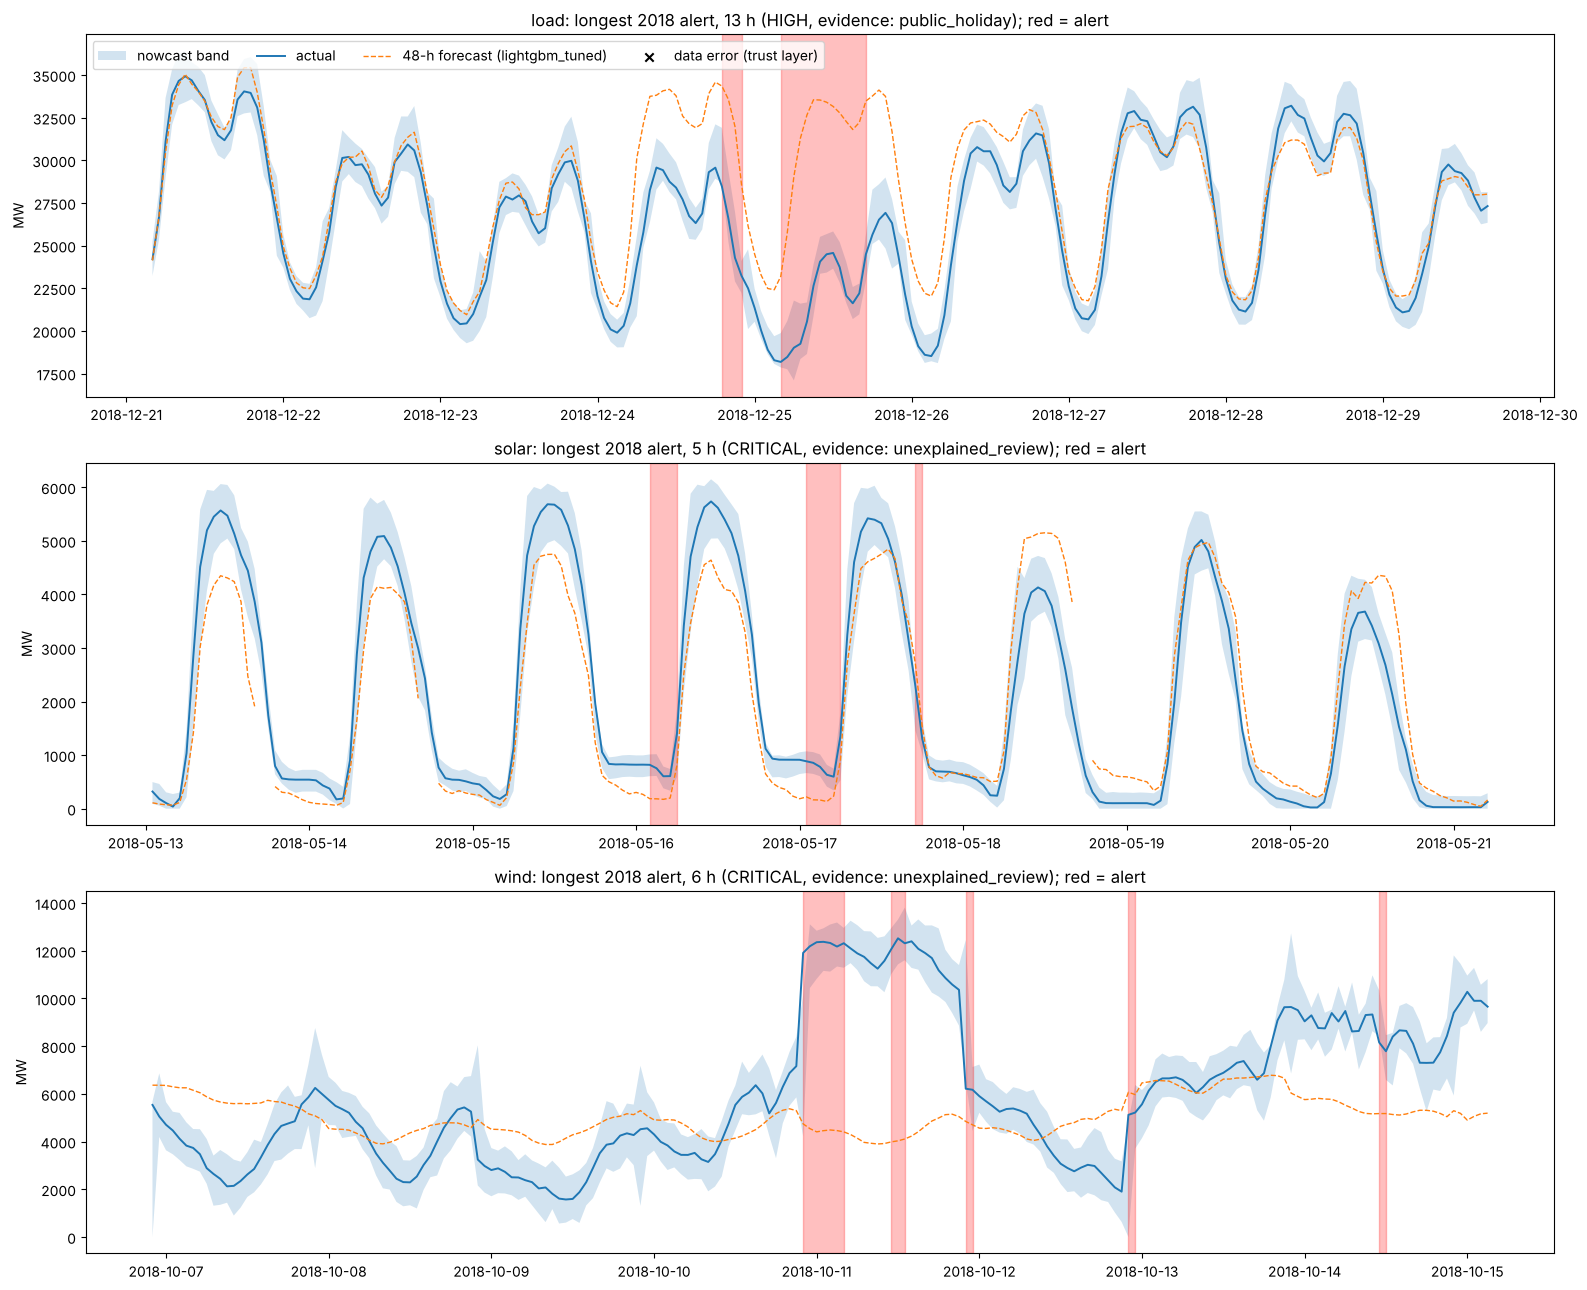

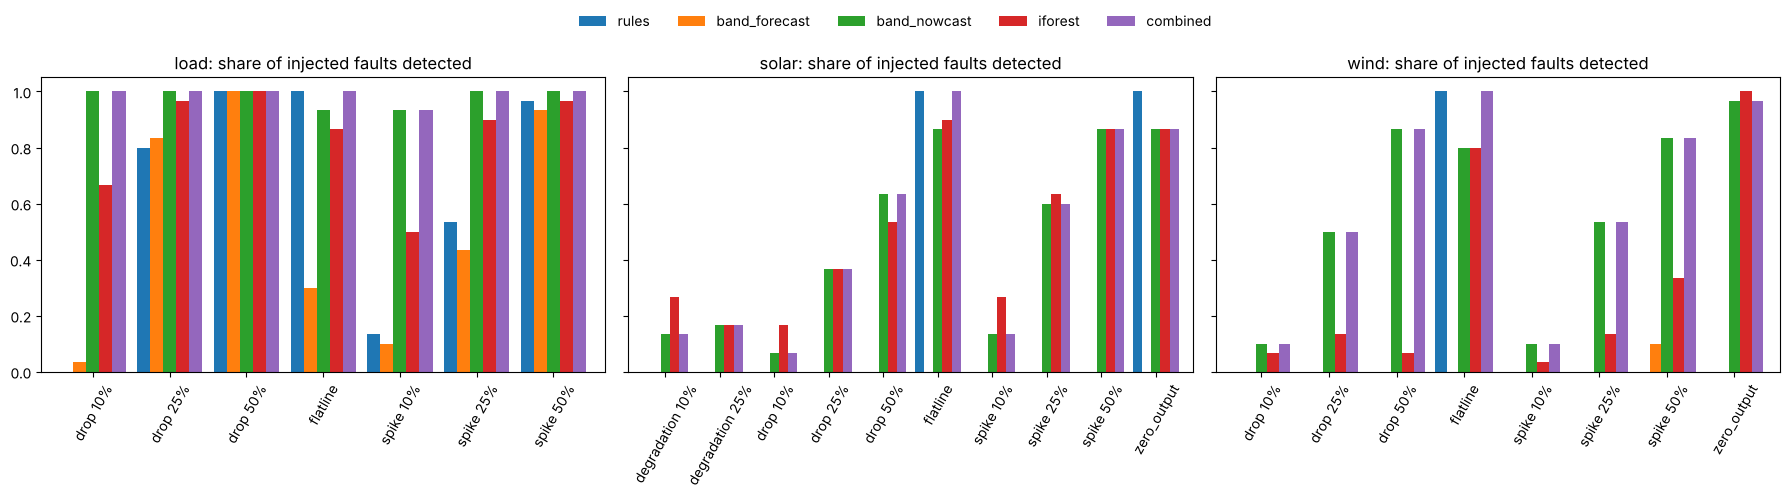

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(16, 13))
for ax, sig in zip(axes, CFG["targets"]):
    fn, ff = test_frames[sig]["nowcast"], test_frames[sig]["forecast"]
    ev = alerts_2018[alerts_2018["signal"] == sig]
    top = ev.sort_values(["hours", "peak_ratio_to_band"], ascending=False).iloc[0]     # longest alert
    w = fn.loc[top["start_utc"] - pd.Timedelta(days=4): top["end_utc"] + pd.Timedelta(days=4)]
    b = bands[(sig, "nowcast")].reindex(w["hour"].to_numpy())
    lo = (w["pred"] + b["lo"].to_numpy()).clip(lower=0 if sig != "load" else None)
    ax.fill_between(w.index, lo, w["pred"] + b["hi"].to_numpy(), alpha=0.2, label="nowcast band")
    ax.plot(w.index, w["actual"], lw=1.4, label="actual")
    ax.plot(w.index, ff.loc[w.index, "pred"], lw=1, ls="--", label=f"48-h forecast ({FORECAST_MODEL[sig]})")
    for _, e in ev[(ev["end_utc"] >= w.index[0]) & (ev["start_utc"] <= w.index[-1])].iterrows():
        ax.axvspan(e["start_utc"], e["end_utc"] + pd.Timedelta(hours=1), color="red", alpha=0.25)
    de = w.index[DQ_ERR[sig].reindex(w.index)]
    ax.scatter(de, w.loc[de, "actual"], marker="x", color="black", zorder=5, label="data error (trust layer)")
    ax.set_title(f"{sig}: longest 2018 alert, {top['hours']} h ({top['severity']}, evidence: {top['evidence']}); red = alert")
    ax.set_ylabel("MW")
axes[0].legend(loc="upper left", ncol=4)
plt.tight_layout()
fig.savefig(ANOM_DIR / "alert_examples_2018.png", dpi=110)
plt.show()

piv = inj_summary.assign(case=lambda d: d["fault"] + d["magnitude"].map(lambda m: "" if pd.isna(m) or m == 1 else f" {m:.0%}"))
methods = ["rules", "band_forecast", "band_nowcast", "iforest", "combined"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, sig in zip(axes, CFG["targets"]):
    piv[piv["signal"] == sig].pivot(index="case", columns="method", values="recall")[methods].plot.bar(ax=ax, rot=60, width=0.85, legend=False)
    ax.set_title(f"{sig}: share of injected faults detected"); ax.set_ylim(0, 1.05); ax.set_xlabel("")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=5, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(ANOM_DIR / "injection_recall.png", dpi=110)
plt.show()

## 4.8 Track the detector in MLflow

In [42]:
# Log the anomaly detector to MLflow (metrics + evaluation files). The serving files are exported in Part 6.
summary_metrics = {f"test_{r.signal}_{r.method}_events_per_week": r.events_per_week
                   for r in alert_rates[alert_rates["split"] == "test"].itertuples()}
summary_metrics |= {f"inject_{s}_{m}_mean_recall": float(g["recall"].mean())
                    for (s, m), g in inj_summary.groupby(["signal", "method"])}
with mlflow.start_run(run_name="anomaly_detector"):
    mlflow.set_tags({"family": "anomaly", "stage": "production"})
    mlflow.log_params({"dataset_version": DATASET_VERSION, "alert_budget": ANOM["alert_budget"], "merge_gap_h": ANOM["merge_gap_h"],
                       "nowcast_lags_h": str(NOW_LAGS), "forecast_models": str(FORECAST_MODEL)})
    mlflow.log_metrics(summary_metrics)
    for p in ["alerts_test_2018.csv", "injection_eval.csv", "alert_rates.csv", "alert_examples_2018.png", "injection_recall.png"]:
        mlflow.log_artifact(str(ANOM_DIR / p), artifact_path="evaluation")
print("Logged run 'anomaly_detector' with", len(summary_metrics), "metrics.")

Logged run 'anomaly_detector' with 30 metrics.


# Part 5 — Business view (new)
Two questions a grid operator asks before using the system: **what is a better forecast worth**, and **what does the alert stream cost and catch**.

**Cost proxy (stated assumption):** a forecast error has to be bought or sold back outside the day-ahead market. We value each MWh of error at that hour's spread between the final price and the day-ahead price, `|price actual - price day ahead|` (EUR/MWh), both in the dataset. Real imbalance settlement rules are more complex, so the figures are an order of magnitude, not a settlement figure. The review cost assumes 10 minutes of analyst time per alert.

## 5.1 Cost of forecast errors and alert workload

In [43]:
BUSINESS = {"cost_basis": "imbalance spread proxy: |price actual - price day ahead| (EUR/MWh) for each hour",
            "review_minutes_per_alert": 10}
_prices = (energy_raw.assign(time_utc=pd.to_datetime(energy_raw["time"], utc=True)).set_index("time_utc")
           [["price actual", "price day ahead"]].reindex(master.index))
PRICE = (_prices["price actual"] - _prices["price day ahead"]).abs()       # EUR per MWh of deviation
print(f"Imbalance spread on 2018: mean {PRICE[master['split_test'].eq(1)].mean():.1f} EUR/MWh")

rows = []
for s in CFG["targets"]:
    d = DATA[s]
    m = d["split"].eq("test")
    y, p = d["y"].loc[m], PRICE.loc[m[m].index]
    for label, name in [("naive (same hour last week)", "naive_168h"), ("our production model", PRODUCTION[s]),
                        ("operator TSO", "tso_day_ahead")]:
        err = (PREDICTIONS[s][name].loc[m] - y).abs()
        rows.append({"signal": s, "forecast": label, "model": name, "hours": int(m.sum()),
                     "error_GWh": err.sum() / 1e3, "cost_proxy_MEUR": float((err * p).sum()) / 1e6})
cost = pd.DataFrame(rows)
cost_p = cost.pivot(index="signal", columns="forecast", values="cost_proxy_MEUR")
value = pd.DataFrame({
    "naive_MEUR": cost_p["naive (same hour last week)"], "ours_MEUR": cost_p["our production model"], "tso_MEUR": cost_p["operator TSO"],
})
value["saving_vs_naive_MEUR"] = value["naive_MEUR"] - value["ours_MEUR"]
value["gap_to_tso_closed_pct"] = 100 * value["saving_vs_naive_MEUR"] / (value["naive_MEUR"] - value["tso_MEUR"])
cost.to_csv(OUT / "business_forecast_cost.csv", index=False)
print("2018 cost of forecast errors, imbalance-spread proxy (million EUR):")
display(value.round(1))

# Alert stream: volume, review workload, what it caught
sev = alerts_2018.groupby(["signal", "severity"]).size().unstack(fill_value=0)
workload = pd.DataFrame({"alerts_2018": alerts_2018.groupby("signal").size(),
                         "high_or_critical": sev.get("HIGH", 0) + sev.get("CRITICAL", 0)})
workload["review_hours_all"] = workload["alerts_2018"] * BUSINESS["review_minutes_per_alert"] / 60
workload["review_hours_high_critical"] = workload["high_or_critical"] * BUSINESS["review_minutes_per_alert"] / 60
workload["data_issue_evidence"] = alerts_2018[alerts_2018["evidence"].isin(
    ["data_quality_rule", "simultaneous_alert_other_signal"])].groupby("signal").size()
print("\nAlert stream on 2018:")
display(workload.fillna(0).round(1))

caught = (inj_summary[inj_summary["method"] == "combined"].groupby(["signal", "fault"])["recall"].mean()
          .unstack().round(2))
print("\nShare of injected faults caught by the alert policy (mean over magnitudes):")
display(caught)
business_summary = {"assumptions": BUSINESS, "forecast_cost_MEUR": value.round(2).reset_index().to_dict(orient="records"),
                    "alert_workload": workload.fillna(0).round(2).reset_index().to_dict(orient="records"),
                    "injected_fault_recall": caught.reset_index().to_dict(orient="records")}
_ = (OUT / "business_summary.json").write_text(json.dumps(business_summary, indent=2, default=float))

Imbalance spread on 2018: mean 8.8 EUR/MWh
2018 cost of forecast errors, imbalance-spread proxy (million EUR):


,naive_MEUR,ours_MEUR,tso_MEUR,saving_vs_naive_MEUR,gap_to_tso_closed_pct
signal,,,,,
load,220.9,165.8,21.3,55.1,27.6
solar,60.8,40.4,11.1,20.4,41.0
wind,298.7,219.7,37.0,79.0,30.2



Alert stream on 2018:


,alerts_2018,high_or_critical,review_hours_all,review_hours_high_critical,data_issue_evidence
signal,,,,,
load,126,42,21.0,7.0,44
solar,101,57,16.8,9.5,47
wind,115,52,19.2,8.7,39



Share of injected faults caught by the alert policy (mean over magnitudes):


fault,degradation,drop,flatline,spike,zero_output
signal,,,,,
load,NaN,1.00,1.0,0.98,NaN
solar,0.15,0.36,1.0,0.53,0.87
wind,NaN,0.49,1.0,0.49,0.97


## 5.2 Recommendations
1. **Use the alert stream as a data-quality gate.** About 2 alerts per signal per week, of which about 1 per week is HIGH or CRITICAL: roughly 25 analyst-hours per year to review the important ones. About a third of 2018 alerts point to data problems (a trust-layer rule fired, or several signals jumped in the same hour). These should be checked before the data feeds planning or settlement.
2. **Use our forecast as an independent second opinion and fallback, not as a replacement.** It closes 28-41 % of the cost gap between a naive forecast and the operator's forecast (spread proxy). Large disagreements with the operator forecast are themselves worth a look.
3. **The biggest accuracy lever is weather forecasts.** Hub-height wind speed and solar irradiance forecasts at the wind and solar regions (for example from Open-Meteo or ECMWF) would replace the calendar-only inputs and target the wind and solar error directly.
4. **Add drift monitoring.** Slow degradation (for example −10 % solar output over a week) is not caught by hourly checks. A weekly actual/expected ratio per signal would cover it, together with the alert rate (recalibrate the bands if it doubles compared with validation).
5. **Retrain on a schedule.** Refit monthly on a rolling window, keep selecting on a held-out period, and register each model in MLflow before it is promoted.

# Part 6 — Serving bundle for the API and the app (new)
Everything the FastAPI service needs is written to `OUT/artifacts/`, in formats that do not depend on the library version that trained them (LightGBM text, XGBoost JSON, linear coefficients in JSON). Every exported model is reloaded and checked against the notebook predictions; `manifest.json` stores the SHA-256 of each file and the library versions. Copy this folder to `gridpulse/artifacts/` in the project repository.

In [44]:
def clean(o):
    """JSON-safe copy: NaN -> None, numpy scalars -> Python numbers, timestamps -> ISO text."""
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (pd.Timestamp,)):
        return o.isoformat()
    return o

ART = OUT / "artifacts"
MODELS_DIR = ART / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

def export_forecast(signal):
    name, est, X = PRODUCTION[signal], FITTED[signal][PRODUCTION[signal]], DATA[signal]["X"]
    if name.startswith("lightgbm"):
        fmt, path = "lightgbm_txt", MODELS_DIR / f"forecast_{signal}.txt"
        est.booster_.save_model(str(path))
        reloaded = lgb.Booster(model_file=str(path)).predict(X)
    elif name == "xgboost":
        fmt, path = "xgboost_json", MODELS_DIR / f"forecast_{signal}.json"
        est.get_booster().save_model(str(path))
        reloaded = xgb.Booster(model_file=str(path)).predict(xgb.DMatrix(X))
    else:
        scaler, linear = est[0], est[-1]
        fmt, path = "linear_json", MODELS_DIR / f"forecast_{signal}.json"
        path.write_text(json.dumps({"features": list(X.columns), "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
                                    "coef": linear.coef_.tolist(), "intercept": float(linear.intercept_)}))
        reloaded = ((X.to_numpy(float) - scaler.mean_) / scaler.scale_) @ linear.coef_ + linear.intercept_
    gap = float(np.abs(reloaded - PREDICTIONS[signal][name].to_numpy()).max())
    assert gap < 0.05, f"{signal}: exported model differs from the notebook model by {gap} MW"
    row = production_summary.loc[signal]
    return {"model": name, "format": fmt, "file": f"models/{path.name}", "features": list(X.columns),
            "validation_MAE": round(float(row["validation_MAE"]), 2), "test_MAE": round(float(row["test_MAE"]), 2),
            "test_nMAE_pct": round(float(row["test_nMAE_pct"]), 2), "naive_test_MAE": round(float(row["naive_test_MAE"]), 2),
            "tso_test_MAE": round(float(row["tso_test_MAE"]), 2), "max_reload_gap_MW": gap}

forecast_spec = {s: export_forecast(s) for s in CFG["targets"]}
for s, m in nowcast_models.items():
    m.booster_.save_model(str(MODELS_DIR / f"nowcast_{s}.txt"))

# Reference data: the raw hourly series the service reads (targets, operator forecasts, prices, 5-city weather means)
energy_full = (energy_raw.assign(time_utc=pd.to_datetime(energy_raw["time"], utc=True)).drop(columns="time")
               .set_index("time_utc").sort_index())
ref = pd.DataFrame(index=energy_full.index)
for s, col in CFG["targets"].items():
    ref[f"{s}_actual"], ref[f"{s}_tso"] = energy_full[col], energy_full[CFG["benchmarks"][s]]
ref["price_day_ahead"], ref["price_actual"] = energy_full["price day ahead"], energy_full["price actual"]
for v in WX_VARS:
    ref[f"wx_{v}"] = wide[city_cols(wide, v)].mean(axis=1).reindex(ref.index)
ref["split"] = "gap"
for name_, (a, b) in bounds.items():
    ref.loc[(ref.index >= a) & (ref.index < b), "split"] = name_
ref.index.name = "time_utc"
ref.to_parquet(ART / "reference_data.parquet")

# Parity files: the service must reproduce these numbers exactly
pd.concat([PREDICTIONS[s][PRODUCTION[s]].rename("forecast_mw").to_frame().assign(signal=s) for s in CFG["targets"]]) \
  .rename_axis("time_utc").reset_index().to_parquet(ART / "parity_forecast.parquet")
pd.concat([test_frames[s]["nowcast"][["pred"]].rename(columns={"pred": "nowcast_mw"})
           .join(test_flags[s][["rules", "band_forecast", "band_nowcast", "combined"]]).assign(signal=s) for s in CFG["targets"]]) \
  .rename_axis("time_utc").reset_index().to_parquet(ART / "parity_anomaly_test.parquet")
alerts_2018.to_csv(ART / "alerts_test_2018.csv", index=False)

config = {
    "dataset_version": DATASET_VERSION, "provenance": provenance,
    "targets": CFG["targets"], "benchmarks": CFG["benchmarks"], "splits": CFG["splits"], "gap_hours": CFG["gap_hours"],
    "trust_rules": {k: CFG[k] for k in ["ranges_mw", "flatline_hours", "solar_night_elevation_deg", "solar_night_max_mw",
                                        "solar_flatline_min_elevation_deg", "solar_midday_elevation_deg", "load_deviation_pct", "site"]},
    "calendar": {"features": CALENDAR_FEATURES, "time_basis": "UTC", "sun_elevation_decimals": 2,
                 "definition": "hour_sin/cos = sin/cos(2*pi*hour/24); month_sin/cos = sin/cos(2*pi*(month-1)/12); "
                               "day_of_week 0=Mon; is_weekend = day_of_week>=5; sun elevation at mid-hour (NOAA)"},
    "forecast": {"lags_h": LAGS, "min_history_h": max(LAGS), "models": forecast_spec},
    "nowcast": {"lags_h": list(NOW_LAGS), "weather_vars": WX_VARS, "history_days": 35,
                "features_in_order": list(nowcast_models["load"].booster_.feature_name()),
                "files": {s: f"models/nowcast_{s}.txt" for s in nowcast_models}},
    "anomaly": {**{k: v for k, v in ANOM.items() if k != "iforest"}, "local_tz": LOCAL_TZ,
                # evidence rule of 4.5: the operator forecast error is in its top 5 % on the test year
                "tso_far_threshold_mw": {s: float((test_frames[s]["nowcast"]["actual"]
                                                   - RAW.loc[test_frames[s]["nowcast"].index, CFG["benchmarks"][s]]).abs().quantile(0.95))
                                         for s in CFG["targets"]},
                "policy": "alert = data_error rule OR nowcast band OR forecast band",
                "bands": {f"{s}/{e}": b.reset_index().to_dict(orient="records") for (s, e), b in bands.items()}},
    "metrics": {"production": production_summary.reset_index().to_dict(orient="records"),
                "validation": validation_results.to_dict(orient="records"), "test": test_results.to_dict(orient="records"),
                "tuning": {s: {"team_cv_MAE": t["team_cv_mae"], "best_cv_MAE": t["best_cv_mae"],
                               "params": {k: v for k, v in t["params"].items() if k != "verbosity"}} for s, t in TUNING.items()},
                "shap_mean_abs_test": shap_table.to_dict()},
    "anomaly_evaluation": {"alert_rates": alert_rates.to_dict(orient="records"),
                           "injection": inj_summary.to_dict(orient="records")},
    "business": business_summary,
}
(ART / "config.json").write_text(json.dumps(clean(config), indent=1, default=str))

import sklearn
manifest = {"dataset_version": DATASET_VERSION, "created_utc": pd.Timestamp.now(tz="UTC").isoformat(),
            "files_sha256": {str(p.relative_to(ART)): sha256_file(p) for p in sorted(ART.rglob("*")) if p.is_file() and p.name != "manifest.json"},
            "trained_with": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                             "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__, "xgboost": xgb.__version__}}
(ART / "manifest.json").write_text(json.dumps(manifest, indent=2))

with mlflow.start_run(run_name="serving_bundle"):
    mlflow.set_tags({"family": "release", "dataset_version": DATASET_VERSION})
    mlflow.log_params({f"forecast_{s}": v["model"] for s, v in forecast_spec.items()})
    mlflow.log_artifacts(str(ART), artifact_path="artifacts")

print("Serving bundle:", ART)
for p in sorted(ART.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(ART)):40s} {p.stat().st_size / 1e6:6.2f} MB")

Serving bundle: /content/gridpulse_outputs/artifacts
  alerts_test_2018.csv                       0.04 MB
  config.json                                0.08 MB
  manifest.json                              0.00 MB
  models/forecast_load.txt                   3.01 MB
  models/forecast_solar.txt                  0.69 MB
  models/forecast_wind.json                  0.00 MB
  models/nowcast_load.txt                    3.32 MB
  models/nowcast_solar.txt                   3.35 MB
  models/nowcast_wind.txt                    3.32 MB
  parity_anomaly_test.parquet                0.37 MB
  parity_forecast.parquet                    1.47 MB
  reference_data.parquet                     1.49 MB
